# IMAP DATA ANALYSIS
##  *TODO LIST*

- [ ] Analysis of time-series data in chosen timespan,
- [ ] Analysis of the data distribution,
- [ ] Linear correlations between parameters from specific instrument,
- [ ] Linear correlations between parameters from different instruments,
- [ ] Non-linear correlations between parameters from specific instrument,
- [ ] Non-linear correlations between parameters from different instruments,
- [ ] PCA Analysis of data per instrument,
- [ ] TSNE Analysis of data per instrument,
- [ ] MI Analysis of data between instruments,

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import os
import cdflib
from pathlib import Path
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates

In [6]:
def print_file_attr(filename:str):
    cdf = cdflib.CDF(filename)
    info = cdf.cdf_info()
    print("=" * 80)
    print("BASIC INFO")
    print("=" * 80)
    print(info)

    print("\n" + "=" * 80)
    print("GLOBAL ATTRIBUTES")
    print("=" * 80)
    global_attrs = cdf.globalattsget()
    if global_attrs:
        for attr_name, values in global_attrs.items():
            print(f"\n{attr_name}:")
            print(f"  {values}")
    else:
        print("No global attributes found.")

    print("\n" + "=" * 80)
    print("VARIABLES")
    print("=" * 80)
    variables = info.zVariables + info.rVariables
    for var_name in variables:
        print(f"\n{'-' * 80}")
        print(f"Variable: {var_name}")
        print("-" * 80)
        var_info = cdf.varinq(var_name)
        print(f"Data type: {var_info.Data_Type_Description}")
        print(f"Dimensions: {var_info.Dim_Sizes}")
        print(f"Number of elements: {var_info.Num_Elements}")
        print(f"Number of records: {var_info.Last_Rec + 1}")
        var_attrs = cdf.varattsget(var_name)
        if var_attrs:
            print("\nAttributes:")
            for attr_name, value in var_attrs.items():
                print(f"  {attr_name}: {value}")
        else:
            print("\nNo variable attributes found.")
        description_fields = ["FIELDNAM", "CATDESC","VAR_NOTES", "LABLAXIS", "UNITS",]
        descriptions = {name: var_attrs[name] for name in description_fields if name in var_attrs}
        if descriptions:
            print("\nDescription:")
            for name, value in descriptions.items():
                print(f"  {name}: {value}")

In [7]:
def plot_time_series(cdf_var_name, data_dir="../raw_data/ARCHIVE/All", component=None, gap_factor=10,plot=True):

    data_dir = Path(data_dir)
    cdf_files = sorted(p for p in data_dir.iterdir() if p.is_file() and p.suffix.lower() == ".cdf")
    if not cdf_files:
        raise FileNotFoundError(f"No CDF files found in {data_dir}")
    all_time = []
    all_values = []
    metadata = None
    files_found = 0
    for file in cdf_files:
        cdf = cdflib.CDF(str(file))
        try:
            variables = cdf.cdf_info().zVariables
            if cdf_var_name not in variables:
                continue
            attrs = cdf.varattsget(cdf_var_name)
            epoch_name = attrs.get("DEPEND_0")
            if not epoch_name or epoch_name not in variables:
                print(f"Skipped {file.name}: missing DEPEND_0")
                continue

            epoch = np.asarray(cdf.varget(epoch_name))
            values = np.asarray(cdf.varget(cdf_var_name))
            if values.ndim == 0 or values.shape[0] != len(epoch):
                print(f"Skipped {file.name}: incompatible time dimension")
                continue

            valid_time = epoch != np.iinfo(np.int64).min
            epoch = epoch[valid_time]
            values = values[valid_time]
            values = values.astype(float, copy=True)
            fill_value = attrs.get("FILLVAL")
            if fill_value is not None:
                values[values == float(fill_value)] = np.nan

            values[~np.isfinite(values)] = np.nan
            if component is not None:
                if isinstance(component, int):
                    component = (component,)
                values = values[(slice(None),) + tuple(component)]
            elif values.ndim > 2:
                raise ValueError(f"{cdf_var_name} has shape {values.shape}; select a component explicitly.")

            if len(epoch) == 0:
                continue

            all_time.append(epoch)
            all_values.append(values)
            files_found += 1
            file_start = cdflib.cdfepoch.to_datetime(epoch.min())
            file_end = cdflib.cdfepoch.to_datetime(epoch.max())
            print(f"{file.name}: {file_start} -> {file_end} ({len(epoch)} samples)")
            if metadata is None:
                metadata = attrs

        except Exception as ex:
            print(ex)

    if not all_time:
        raise ValueError(f"No valid data found for '{cdf_var_name}'.")

    print(f"\nFiles used: {files_found}/{len(cdf_files)}")

    all_time = np.concatenate(all_time)
    all_values = np.concatenate(all_values, axis=0)
    order = np.argsort(all_time)
    all_time = all_time[order]
    all_values = all_values[order]
    time = cdflib.cdfepoch.to_datetime(all_time)

    if all_values.ndim == 1:
        all_values = all_values[:, None]
    else:
        all_values = all_values.reshape(len(all_values), -1)

    if len(all_time) > 1 and gap_factor is not None:
        differences = np.diff(all_time)
        positive_differences = differences[differences > 0]

        if len(positive_differences):
            median_dt = np.median(positive_differences)
            gap_indices = np.where(differences > gap_factor * median_dt)[0]
            all_values[gap_indices + 1, :] = np.nan

    label = metadata.get("LABLAXIS", cdf_var_name)
    units = metadata.get("UNITS", "")
    description = metadata.get("CATDESC", cdf_var_name)
    if plot:
        fig, ax = plt.subplots(figsize=(16, 7))

        for i in range(all_values.shape[1]):
            line_label = (label if all_values.shape[1] == 1 else f"{label} — component {i}")
            ax.plot(time, all_values[:, i], linewidth=0.8, label=line_label,)

        ax.set_title(f"{description}\n({cdf_var_name})")
        ax.set_xlabel("Time")
        ax.set_ylabel(f"{label} [{units}]" if str(units).strip() else label)
        ax.grid(True, alpha=0.3)
        if all_values.shape[1] > 1:
            ax.legend()

        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()
    columns = ([cdf_var_name] if all_values.shape[1] == 1 else [f"{cdf_var_name}_{i}" for i in range(all_values.shape[1])])
    return pd.DataFrame(all_values, index=pd.DatetimeIndex(time, name="time"), columns=columns,)

## File Data description
First, it is necessary to understand the data structure of the cdf files, what attributes, variables and data types are stored inside them.

In [8]:
print_file_attr("../raw_data/ARCHIVE/All/imap_ialirt_l1_realtime_20261003_v001.cdf")

BASIC INFO
CDFInfo(CDF=WindowsPath('D:/Moje dane/Programy Python/IMAP/raw_data/ARCHIVE/All/imap_ialirt_l1_realtime_20261003_v001.cdf'), Version='3.9.0', Encoding=6, Majority='Row_major', rVariables=[], zVariables=['codice_hi_h', 'codice_lo_c_over_o_abundance', 'codice_lo_mg_over_o_abundance', 'codice_lo_fe_over_o_abundance', 'codice_lo_c_plus_6_over_c_plus_5', 'codice_lo_o_plus_7_over_o_plus_6', 'codice_lo_fe_low_over_fe_high', 'hit_e_a_side_med_en', 'hit_e_b_side_med_en', 'hit_h_omni_low_en', 'hit_h_omni_med_en', 'hit_he_omni_low_en', 'hit_he_omni_high_en', 'mag_B_magnitude', 'mag_theta_B_GSE', 'mag_phi_B_GSE', 'mag_theta_B_GSM', 'mag_phi_B_GSM', 'mag_B_GSE', 'mag_B_GSM', 'mag_B_RTN', 'swapi_pseudo_proton_density', 'swapi_pseudo_proton_speed', 'swapi_pseudo_proton_temperature', 'swe_normalized_counts', 'swe_counterstreaming_electrons', 'sc_position_GSE', 'sc_velocity_GSE', 'sc_position_GSM', 'sc_velocity_GSM', 'codice_hi_epoch', 'codice_lo_epoch', 'hit_epoch', 'mag_epoch', 'swapi_epoc

### MAG
MAG - Magnetometer - is a one of the most basic instruments found on IMAP. This device monitors changes in the magnetic field in the proximity of the spacecraft. Because of its design where the detector is attached to the boom situated away from the spacecraft itself, it detects only the environmental changes of the magnetic fields without the magnetic field generated by the spacecraft.
We are going to check how $B$ (magnitude) changes in relation to time and position of the IMAP satellite.

GSE explenation [here](https://www.researchgate.net/figure/The-diagram-shows-the-Geocentric-Solar-Ecliptic-GSE-coordinate-system-centered-at-the_fig1_334136287)


![GSE diagram](../res/GSE.png)


Lisajous curves around the L1 point

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

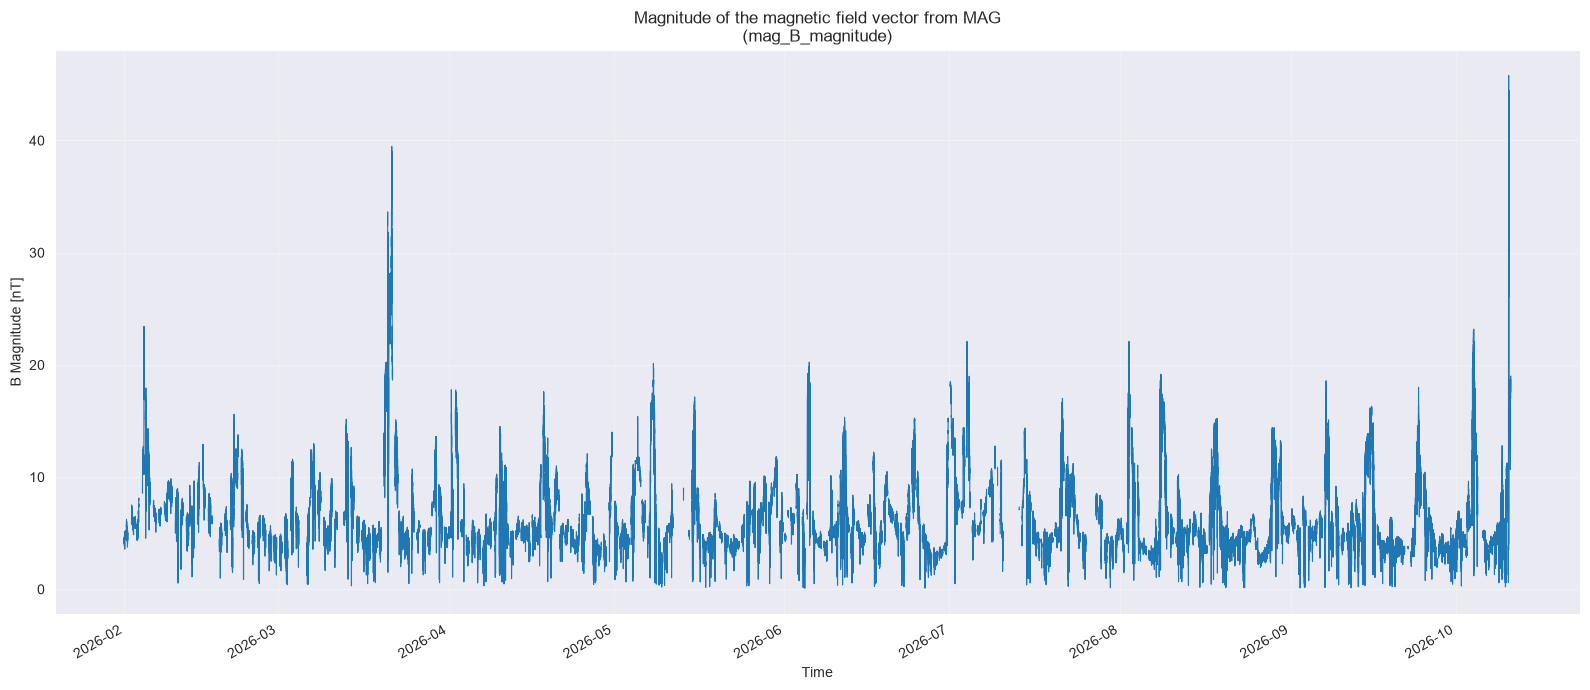

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

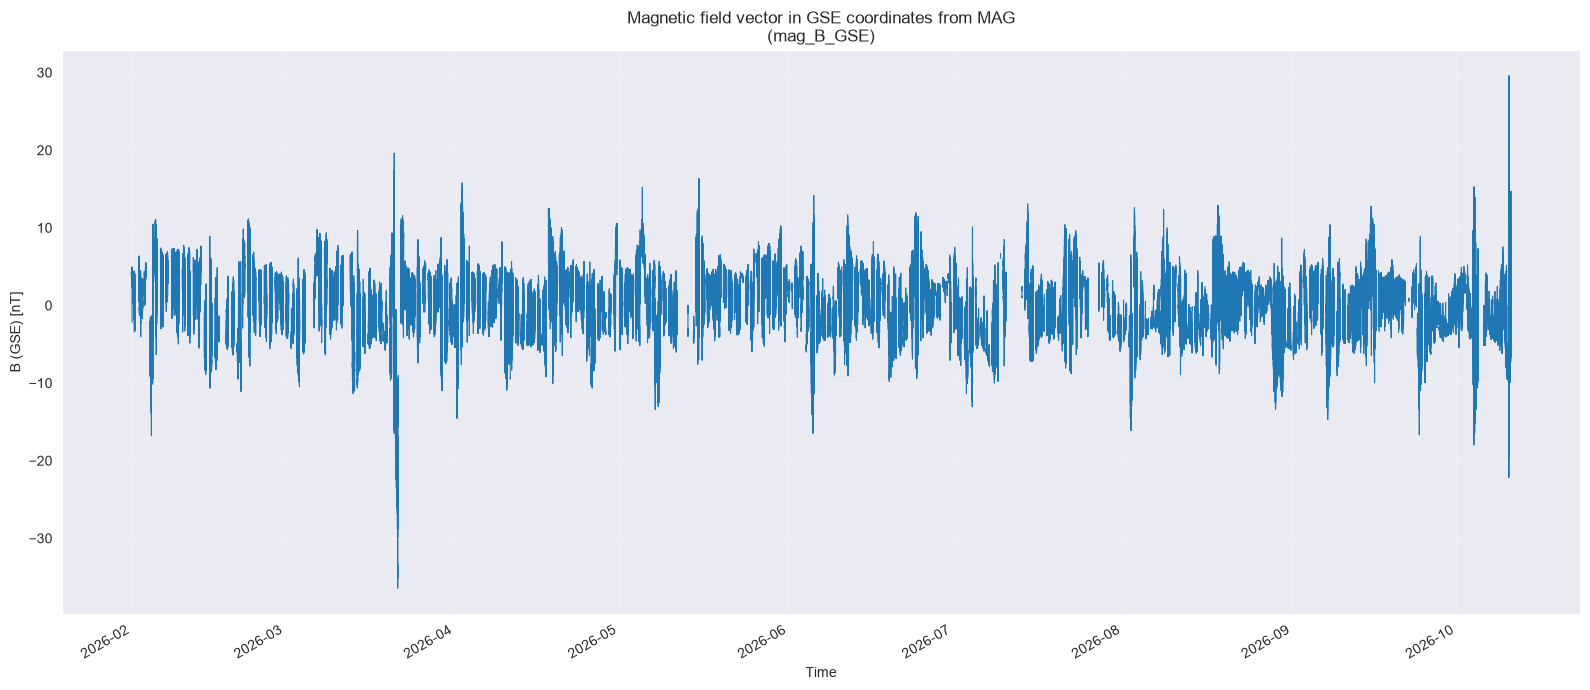

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

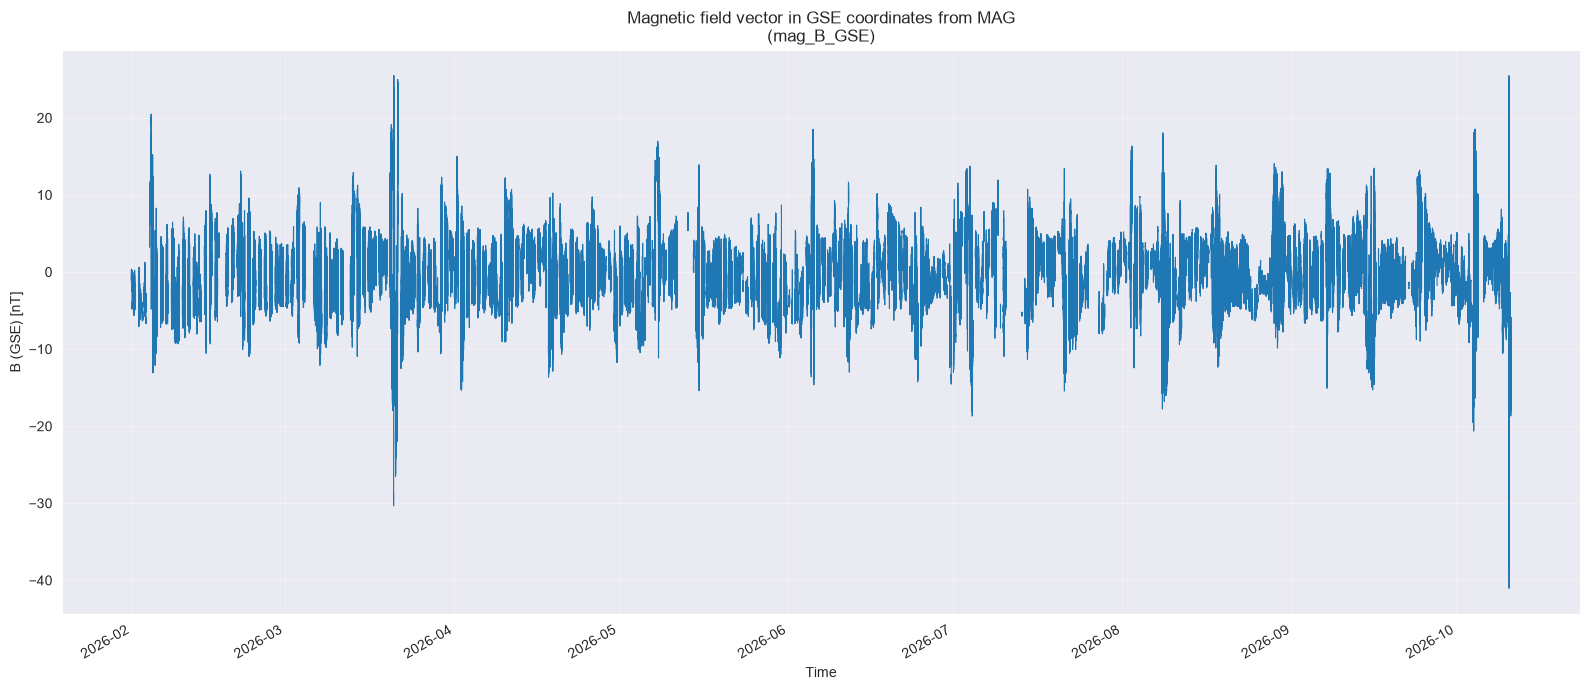

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

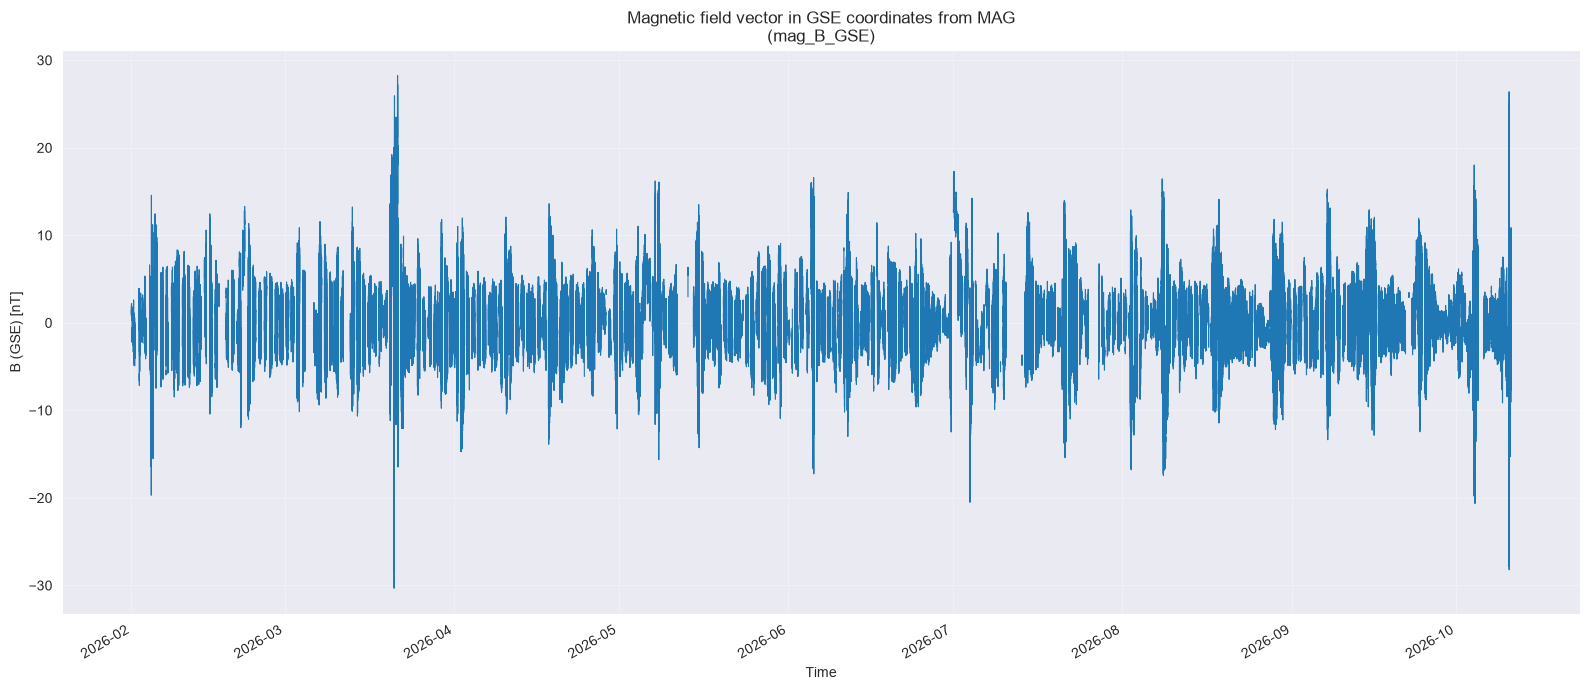

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

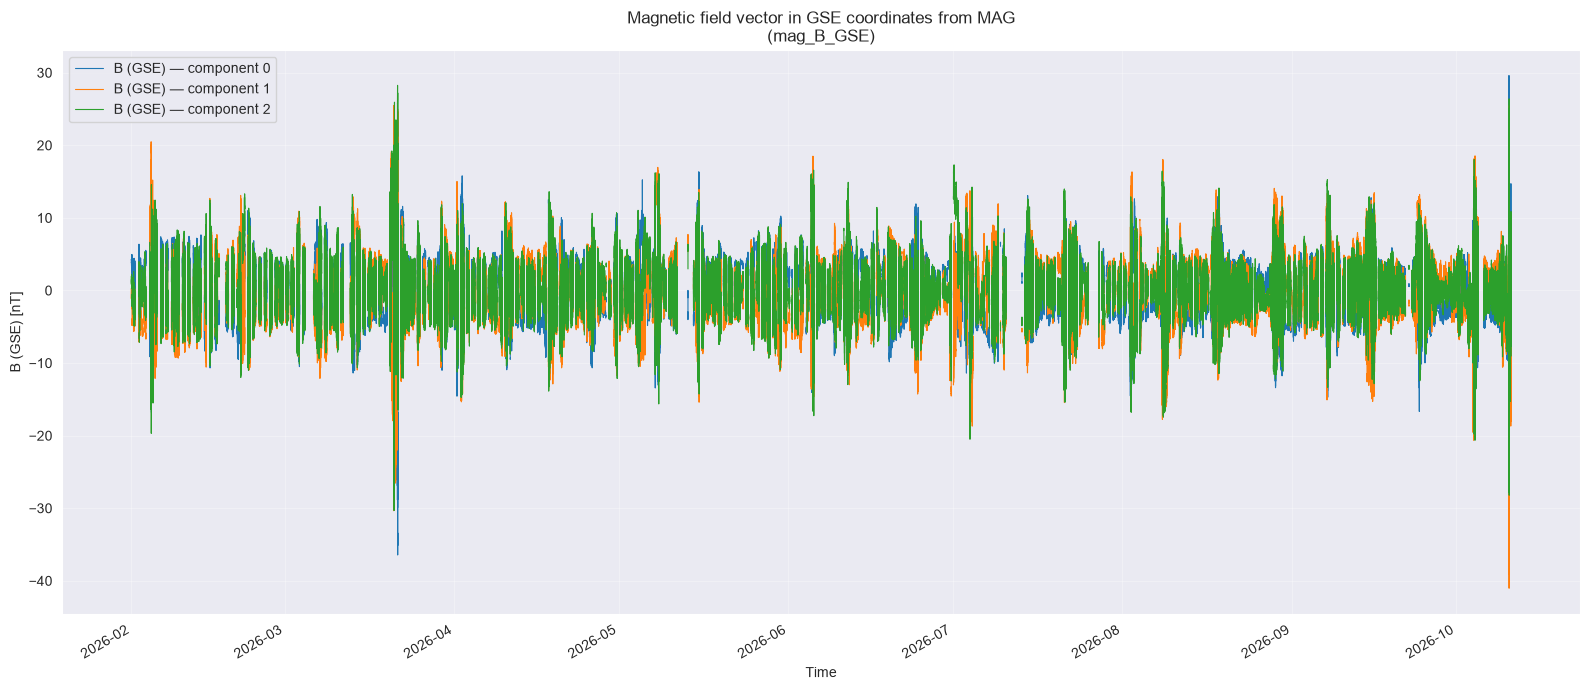

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

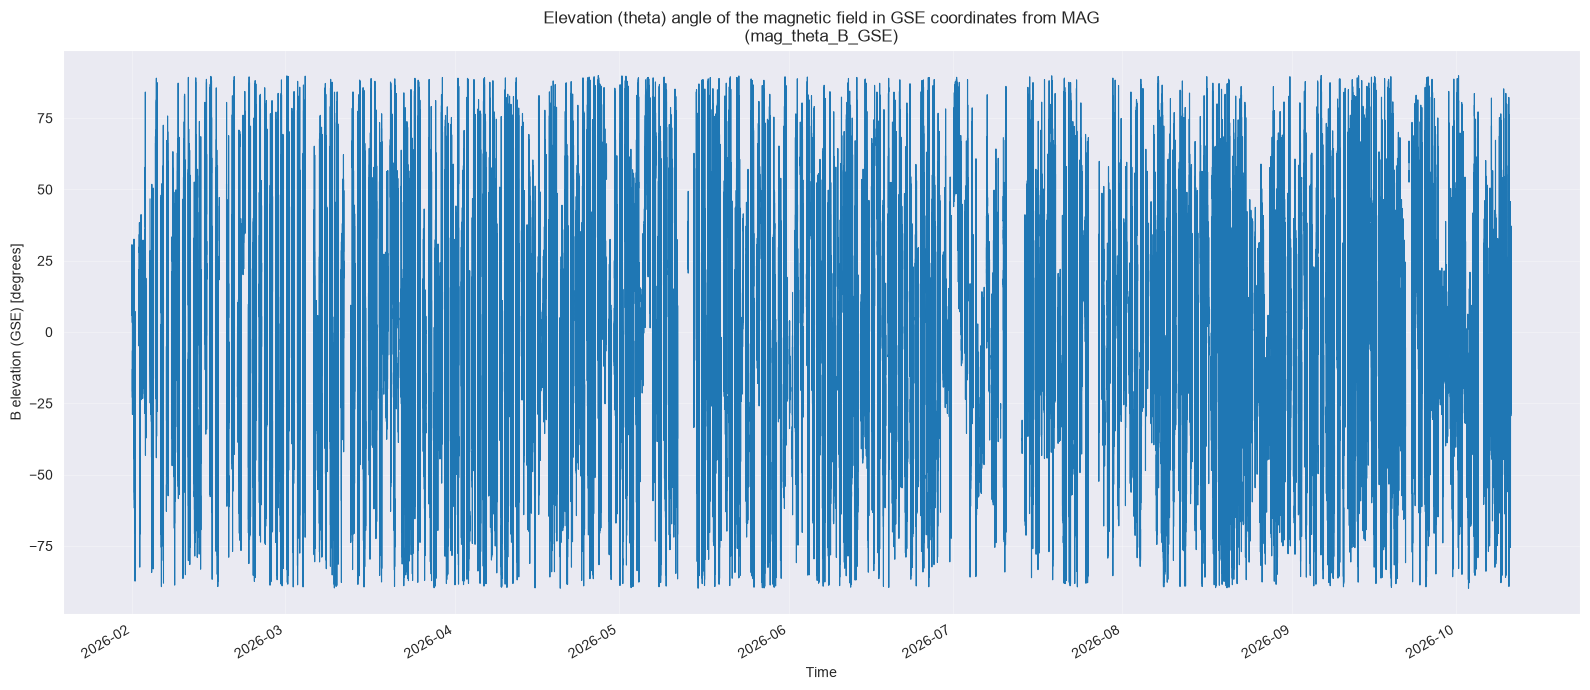

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

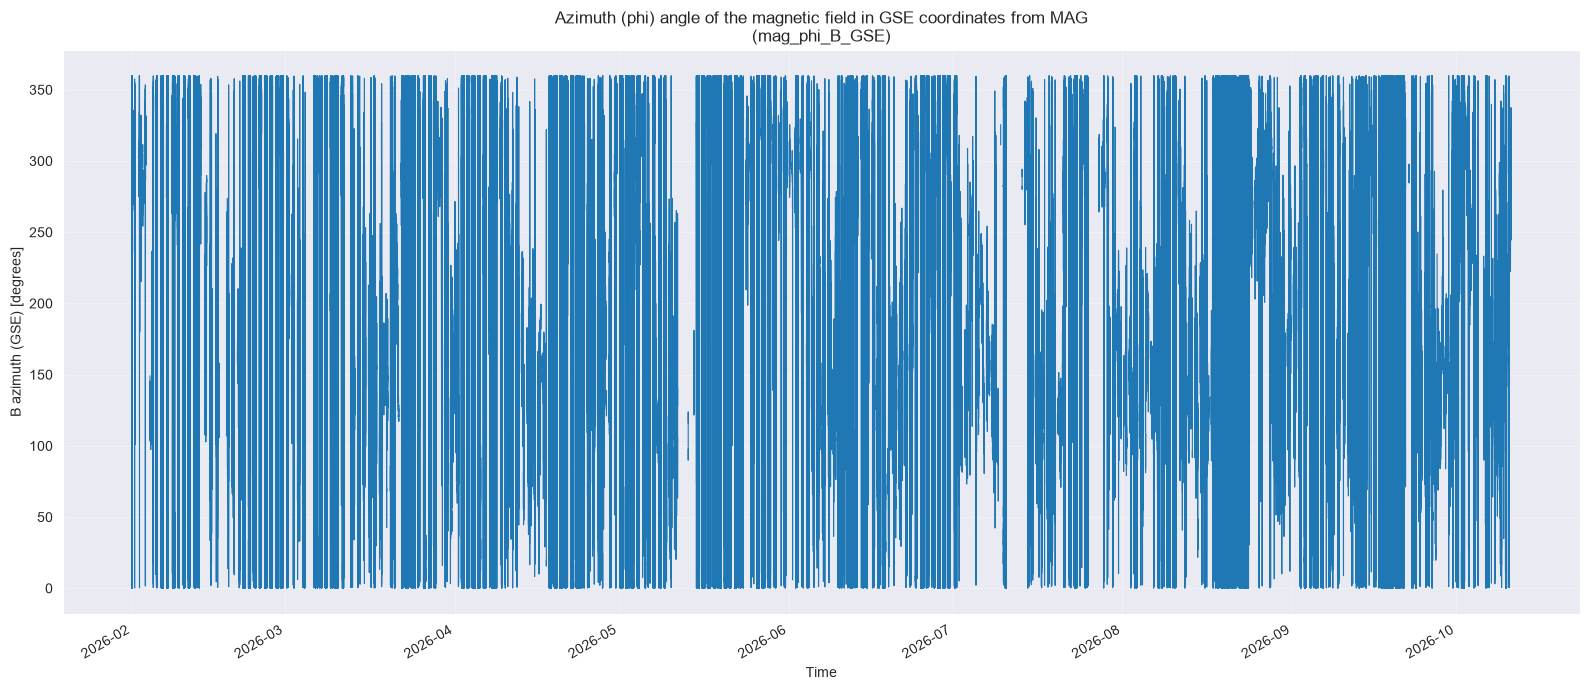

In [9]:
df = plot_time_series("mag_B_magnitude")
df2 = plot_time_series("mag_B_GSE", component=0)
df3 = plot_time_series("mag_B_GSE", component=1)
df4 = plot_time_series("mag_B_GSE", component=2)
df5 = plot_time_series("mag_B_GSE")
df6 = plot_time_series("mag_theta_B_GSE")
df7 = plot_time_series("mag_phi_B_GSE")



## HIT
HIT - High-energy Ion Telescope

This instrument collects a variety of particles generated by the solar wind. Because of its design consisting of multiple aparatures/openings leading to silicon-based detectors this device can not only detect but define the type of a detected ion.

Analyzed attributes:
- hit_e_a_side_med_en - Electrons under 1MeV from A-side
- hit_e_b_side_med_en - Electrons under 1MeV from B-side
- hit-h-omni-low-en - Protons from 6-8MeV, Omni
- hit-h-omni-med-en - Protons from 12-15MeV Omni
- hit_he_omni_low_en - Helium from 6-8MeV/nuc Omni
- hit_he_omni_high_en - helium from 15-70MeV/nuc Omni

In [10]:
HIT_VARIABLES = {
    "electrons": {
        "title": "HIT - Electron count rates",
        "variables":[
            "hit_e_a_side_med_en",
            "hit_e_b_side_med_en",
        ],
        "labels": [
            "Electrons A-side(<1 Mev)",
            "Electrons B-side(<1 Mev)",
        ],
    },
    "protons": {
        "title": "HIT - Proton count rates",
        "variables":[
            "hit_h_omni_low_en",
            "hit_h_omni_med_en",
        ],
        "labels": [
            "H+ (6-8 Mev)",
            "H+ (12-15 Mev)",
        ],
    },
    "helium": {
        "title": "HIT - Helium count rates",
        "variables":[
            "hit_he_omni_low_en",
            "hit_he_omni_high_en",
        ],
        "labels": [
            "He_4 (6-8 MeV)",
            "He_4 (15-70 MeV)",
        ],
    },
}

def plot_hit_time_series(data_dir="../raw_data/ARCHIVE/All", gap_factor=10):
    results={}
    for particle, config in HIT_VARIABLES.items():
        fig, ax = plt.subplots(figsize=(16,7))
        for var_name, label in zip(config["variables"], config["labels"]):
            df = plot_time_series(var_name, data_dir=data_dir, gap_factor=gap_factor, plot=False)
            results[var_name] = df
            ax.plot(df.index, df.iloc[:,0], linewidth=0.8, label=label)
        ax.set_title(config["title"])
        ax.set_xlabel("Time")
        ax.set_ylabel("Counts")
        ax.grid(True, alpha=0.3)
        ax.legend()

        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()
    return results

imap_ialirt_l1_realtime_20260219_v001.cdf: ['2026-02-19T07:24:11.235798912'] -> ['2026-02-19T17:43:11.203187072'] (615 samples)
imap_ialirt_l1_realtime_20260220_v001.cdf: ['2026-02-20T07:22:11.159906688'] -> ['2026-02-20T23:58:11.107356544'] (758 samples)
imap_ialirt_l1_realtime_20260221_v001.cdf: ['2026-02-21T07:19:11.084055040'] -> ['2026-02-21T16:49:11.054029696'] (568 samples)
imap_ialirt_l1_realtime_20260222_v001.cdf: ['2026-02-22T07:16:11.008243840'] -> ['2026-02-22T16:52:10.977825408'] (574 samples)
imap_ialirt_l1_realtime_20260223_v001.cdf: ['2026-02-23T04:12:10.941914880'] -> ['2026-02-23T16:55:10.901785600'] (758 samples)
imap_ialirt_l1_realtime_20260224_v001.cdf: ['2026-02-24T07:10:10.856659584'] -> ['2026-02-24T17:09:10.825040512'] (421 samples)
imap_ialirt_l1_realtime_20260225_v001.cdf: ['2026-02-25T06:52:10.781602816'] -> ['2026-02-25T17:11:10.748932224'] (618 samples)
imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:52:10.708767104'] -> ['2026-02-26T17:13:10.67

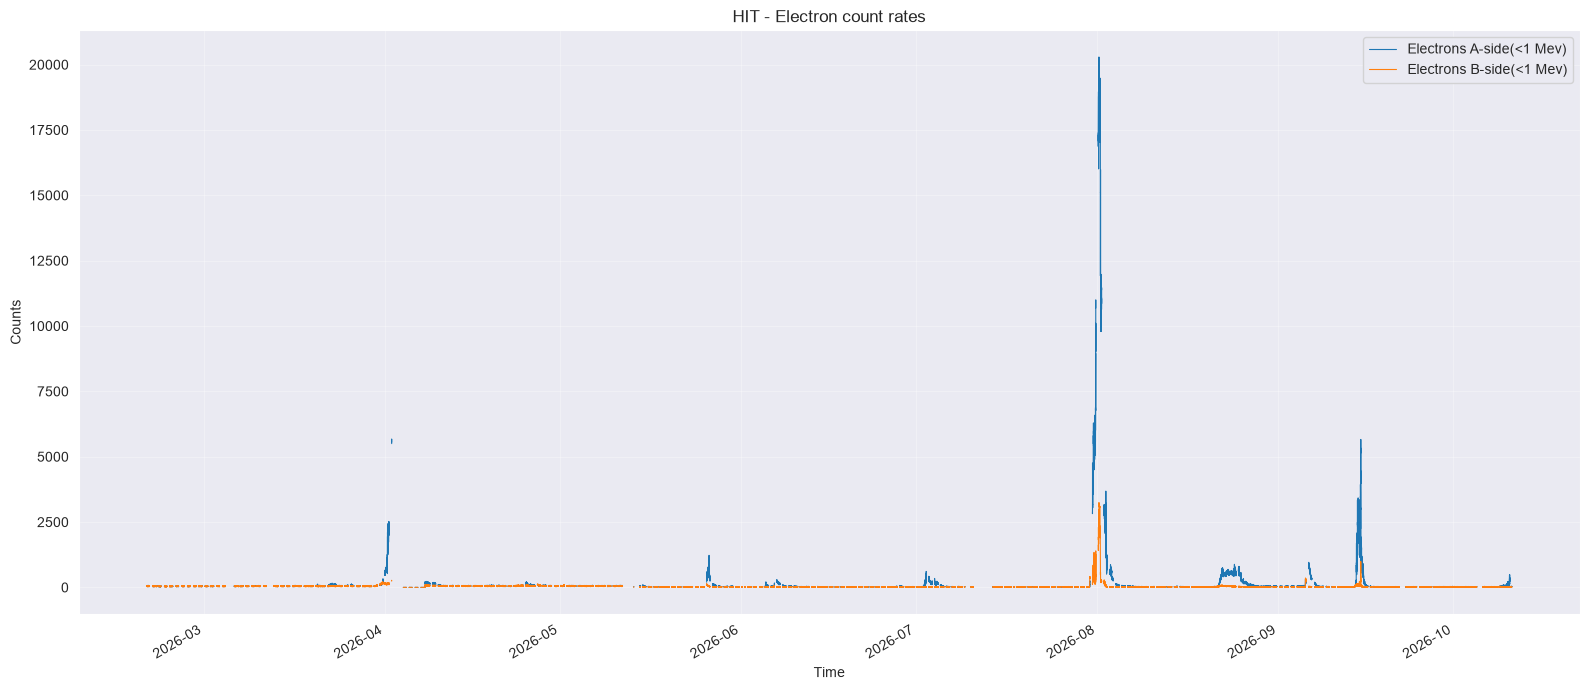

imap_ialirt_l1_realtime_20260219_v001.cdf: ['2026-02-19T07:24:11.235798912'] -> ['2026-02-19T17:43:11.203187072'] (615 samples)
imap_ialirt_l1_realtime_20260220_v001.cdf: ['2026-02-20T07:22:11.159906688'] -> ['2026-02-20T23:58:11.107356544'] (758 samples)
imap_ialirt_l1_realtime_20260221_v001.cdf: ['2026-02-21T07:19:11.084055040'] -> ['2026-02-21T16:49:11.054029696'] (568 samples)
imap_ialirt_l1_realtime_20260222_v001.cdf: ['2026-02-22T07:16:11.008243840'] -> ['2026-02-22T16:52:10.977825408'] (574 samples)
imap_ialirt_l1_realtime_20260223_v001.cdf: ['2026-02-23T04:12:10.941914880'] -> ['2026-02-23T16:55:10.901785600'] (758 samples)
imap_ialirt_l1_realtime_20260224_v001.cdf: ['2026-02-24T07:10:10.856659584'] -> ['2026-02-24T17:09:10.825040512'] (421 samples)
imap_ialirt_l1_realtime_20260225_v001.cdf: ['2026-02-25T06:52:10.781602816'] -> ['2026-02-25T17:11:10.748932224'] (618 samples)
imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:52:10.708767104'] -> ['2026-02-26T17:13:10.67

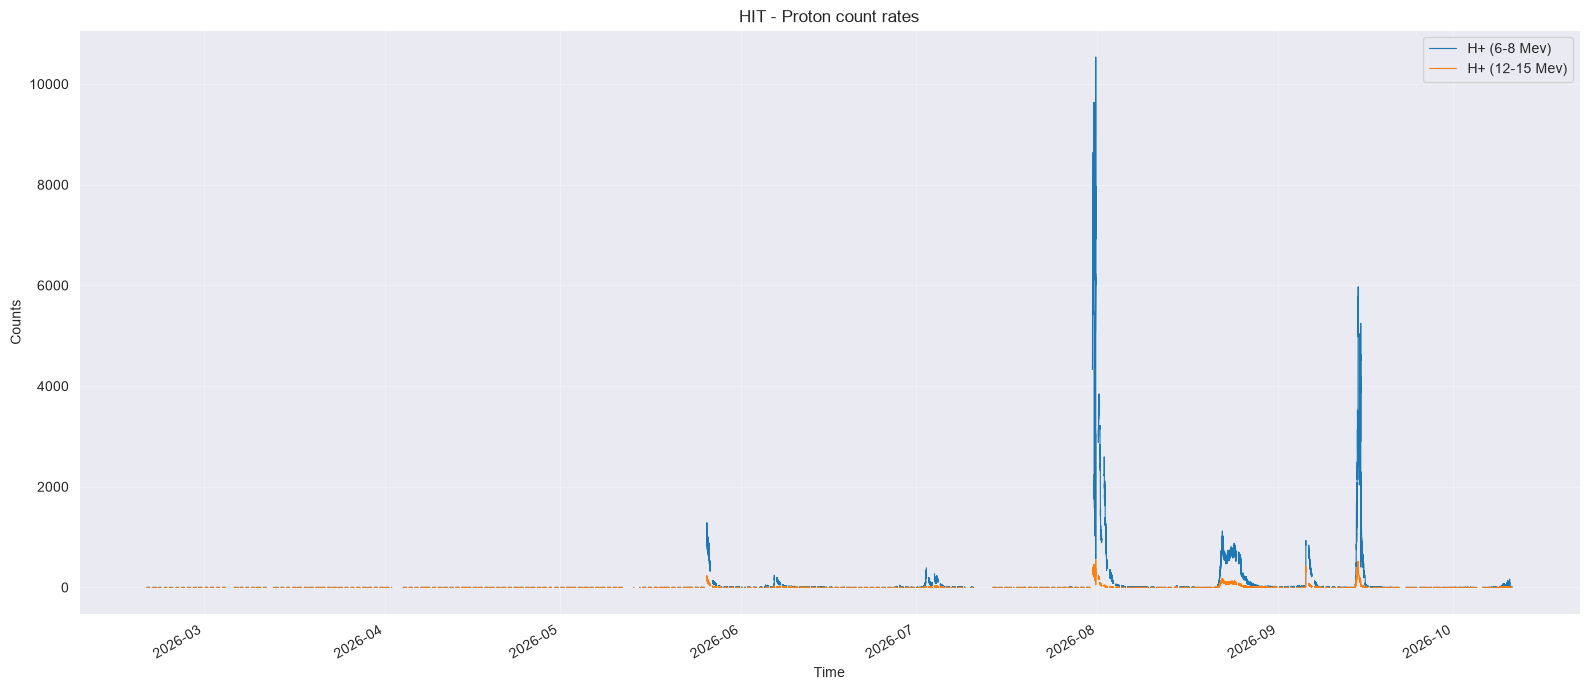

imap_ialirt_l1_realtime_20260219_v001.cdf: ['2026-02-19T07:24:11.235798912'] -> ['2026-02-19T17:43:11.203187072'] (615 samples)
imap_ialirt_l1_realtime_20260220_v001.cdf: ['2026-02-20T07:22:11.159906688'] -> ['2026-02-20T23:58:11.107356544'] (758 samples)
imap_ialirt_l1_realtime_20260221_v001.cdf: ['2026-02-21T07:19:11.084055040'] -> ['2026-02-21T16:49:11.054029696'] (568 samples)
imap_ialirt_l1_realtime_20260222_v001.cdf: ['2026-02-22T07:16:11.008243840'] -> ['2026-02-22T16:52:10.977825408'] (574 samples)
imap_ialirt_l1_realtime_20260223_v001.cdf: ['2026-02-23T04:12:10.941914880'] -> ['2026-02-23T16:55:10.901785600'] (758 samples)
imap_ialirt_l1_realtime_20260224_v001.cdf: ['2026-02-24T07:10:10.856659584'] -> ['2026-02-24T17:09:10.825040512'] (421 samples)
imap_ialirt_l1_realtime_20260225_v001.cdf: ['2026-02-25T06:52:10.781602816'] -> ['2026-02-25T17:11:10.748932224'] (618 samples)
imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:52:10.708767104'] -> ['2026-02-26T17:13:10.67

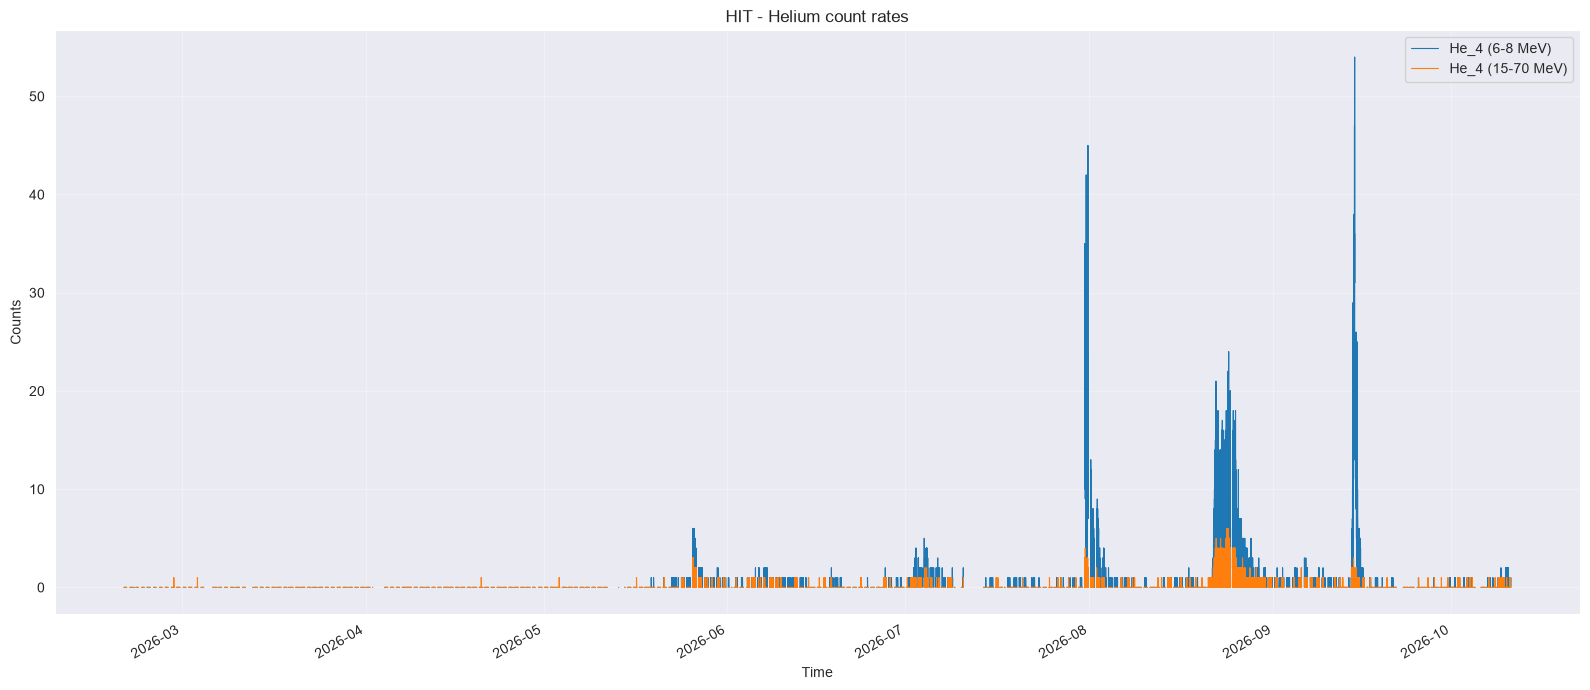

In [20]:
hit_data = plot_hit_time_series()

## CoDICE
CoDICE is an instrument which collects and counts two parts of particles: ones from the solar wind and the other - pick up ions which are the product of interference between solar plasma and interstellar medium.


### Analyzed attributes:
- codice_hi_epoch - proton flux split between 15 energy channels,
- codice_lo_c_over_o_abundance - Abundance ratio between C and O ions,
- codice_lo_mg_over_o_abundance - Abundance ratio between Mg and O ions,
- codice_lo_fe_over_o_abundance - Abundance ratio between Fe and O ions,
- codice_lo_c_plus_6_over_c_plus_5 - Ionisation ratio between $C^{6+}$ and $C^{5+}$ ions,
- codice_lo_o_plus_7_over_o_plus_6 - Ionisation ratio between $O^{7+}$ and $O^{6+}$,
- codice_lo_fe_low_over_fe_high - Ratio between highly ionized Fe and low ionized Fe,


In [28]:
def plot_codice_hi(data_dir = "../raw_data/ARCHIVE/All", gap_factor=10, log_scale = True):
    data_dir = Path(data_dir)
    cdf_files = sorted(p for p in data_dir.iterdir() if p.is_file() and p.suffix.lower() == ".cdf")
    all_time = []
    all_flux = []
    energy_centers = None
    files_found = 0
    for file in cdf_files:
        cdf = cdflib.CDF(str(file))
        try:
            info = cdf.cdf_info()
            variables = info.zVariables + info.rVariables
            if "codice_hi_h" not in variables:
                continue
            attrs = cdf.varattsget("codice_hi_h")
            epoch_name=attrs.get("DEPEND_0")
            if not epoch_name or epoch_name not in variables:
                continue

            epoch = np.asarray(cdf.varget(epoch_name))
            flux=np.asarray(cdf.varget("codice_hi_h"))
            fill_value=attrs.get("FILLVAL")
            if fill_value is not None:
                flux[flux==np.float32(fill_value)] = np.nan
            flux[~np.isfinite(flux)] = np.nan
            valid_min = attrs.get("VALIDMIN")
            valid_max = attrs.get("VALIDMAX")
            if valid_min is not None:
                flux[flux<valid_min] = np.nan
            if valid_max is not None:
                flux[flux>valid_max] = np.nan
            if len(epoch)==0:
                continue

            flux = np.nanmean(flux, axis=(2,3))
            all_time.append(epoch)
            all_flux.append(flux)
            files_found += 1
            if energy_centers is None:
                energy_centers = np.asarray(cdf.varget("codice_hi_energy_center")).squeeze()
                print(f"{file.name}\n{cdflib.cdfepoch.to_datetime(epoch.min())}->{cdflib.cdfepoch.to_datetime(epoch.max())}\n({len(epoch)} samples")
        except Exception as ex:
            print(f"Error in {file.name}: {ex}")

    if not all_time:
         raise ValueError("No valid CoDICE-Hi data found.")
    all_time = np.concatenate(all_time)
    all_flux = np.concatenate(all_flux, axis=0)
    order=np.argsort(all_time)
    all_time = all_time[order]
    all_flux = all_flux[order]
    time=cdflib.cdfepoch.to_datetime(all_time)
    if len(all_time)>1 and gap_factor is not None:
        differences = np.diff(all_time)
        positive_differences = differences[differences>0]
        if len(positive_differences):
            median_dt = np.median(positive_differences)
            gap_indices = np.where(differences > gap_factor * median_dt)[0]
            all_flux[gap_indices+1,:] = np.nan
    print(f"\nFiles used: {files_found}/{len(cdf_files)}")
    columns = [f"{energy:.4f} MeV" for energy in energy_centers]
    df = pd.DataFrame(all_flux, index=pd.DatetimeIndex(time, name="time"), columns=columns,)
    fig, ax = plt.subplots(figsize=(16, 7))
    for i, energy in enumerate(energy_centers):
        ax.plot(time, all_flux[:,i], linewidth=0.8, label=f"{energy:.3f} MeV")
    ax.set_title("CoDICE-Hi — Proton differential intensity")
    ax.set_xlabel("Time")
    ax.set_ylabel("Intensity [counts/cm^2 sr s MeV]")
    if log_scale:
        ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Energy", ncol=3, fontsize=8)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
    return df


Error in imap_ialirt_l1_realtime_20260201_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260202_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260203_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260204_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260205_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260206_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260207_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260208_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260209_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260210_v001.cdf: assignment destination is read-only
imap_ialirt_l1_realtime_20260211_v001.cdf
['2026-02-11T07:32:50.721890816']->['2026-02-11T16:11:49.812089472']
(392 samp

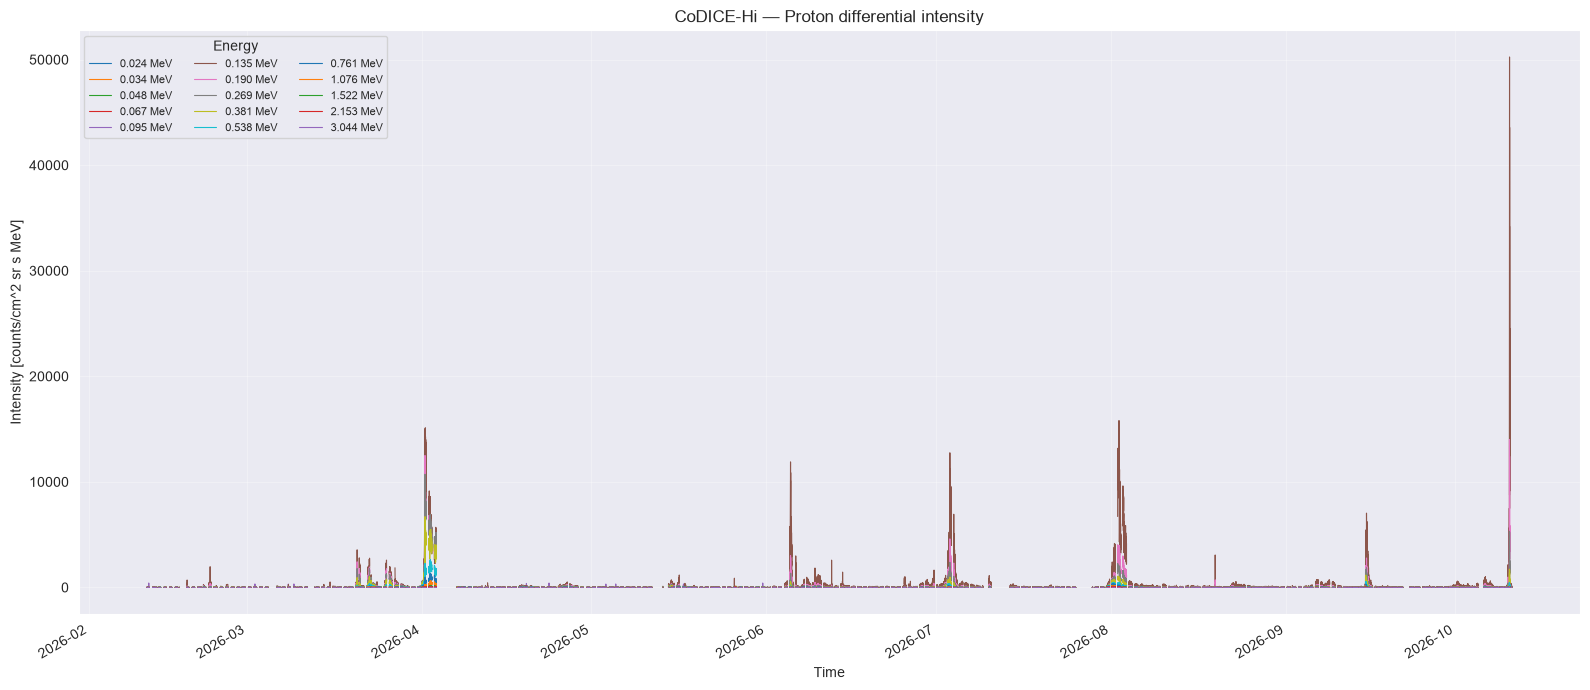

Error in imap_ialirt_l1_realtime_20260201_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260202_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260203_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260204_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260205_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260206_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260207_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260208_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260209_v001.cdf: assignment destination is read-only
Error in imap_ialirt_l1_realtime_20260210_v001.cdf: assignment destination is read-only
imap_ialirt_l1_realtime_20260211_v001.cdf
['2026-02-11T07:32:50.721890816']->['2026-02-11T16:11:49.812089472']
(392 samp

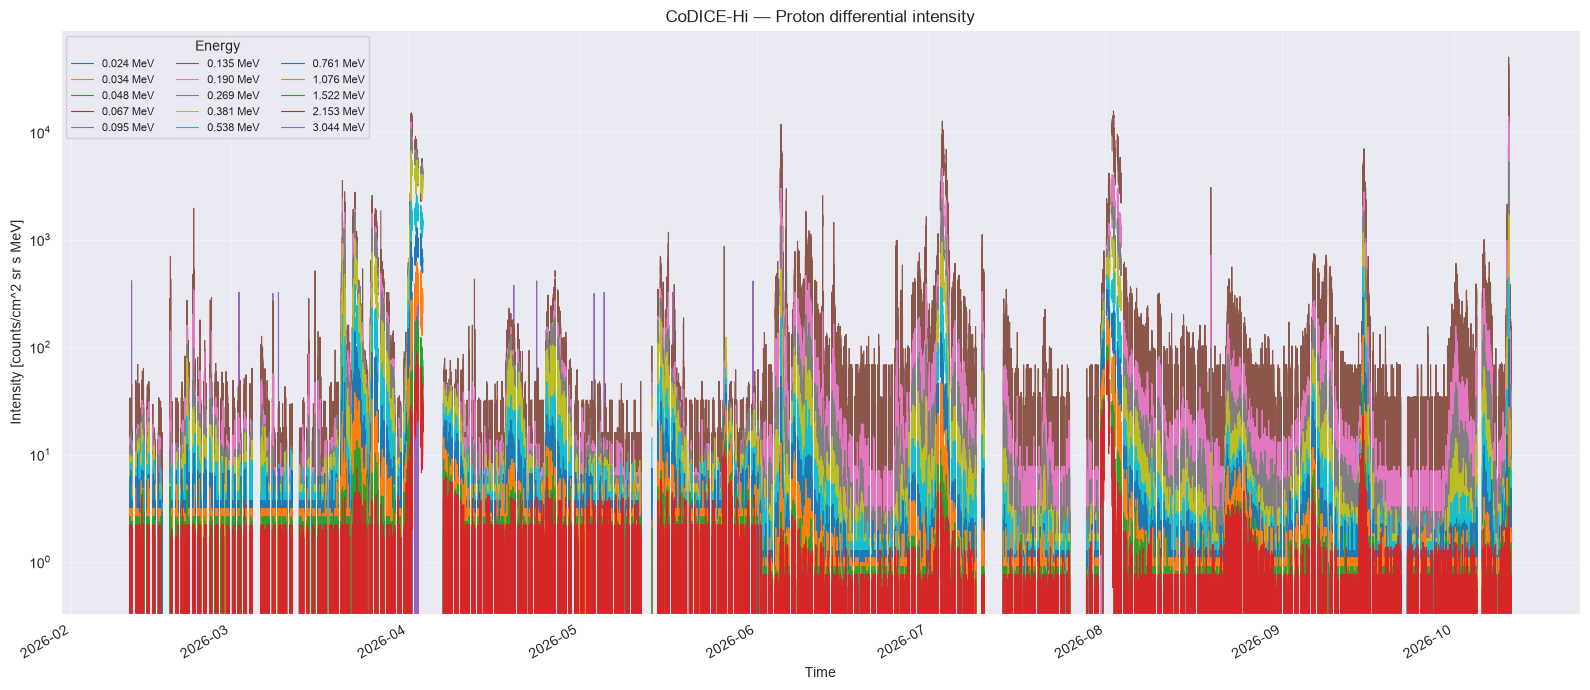

In [29]:
codice_hi=plot_codice_hi(data_dir="../raw_data/ARCHIVE/All", log_scale=False)
codice_hi_log=plot_codice_hi(data_dir="../raw_data/ARCHIVE/All", log_scale=True)

In [30]:
CODICE_LO_VARIABLES = {
    "elemental_abundance": {
        "title": "CoDICE-Lo - Elemental abundance ratios",
        "variables":[
            "codice_lo_c_over_o_abundance",
            "codice_lo_mg_over_o_abundance",
            "codice_lo_fe_over_o_abundance",
        ],
    },
    "charge_states":{
        "title": "CoDICE-Lo - Charge state ratios",
        "variables": [
            "codice_lo_c_plus_6_over_c_plus_5",
            "codice_lo_o_plus_7_over_o_plus_6",
            "codice_lo_fe_low_over_fe_high",
        ],
    },
}
def plot_codice_lo(data_dir="../raw_data/ARCHIVE/All", gap_factor=10, log_scale=True):
    results = {}
    for group, config in CODICE_LO_VARIABLES.items():
        print(f"\n{'=' * 70}")
        print(config["title"])
        print("=" * 70)
        for var_name in config["variables"]:
            df = plot_time_series(var_name, data_dir=data_dir, gap_factor=gap_factor)
            results[var_name] = df
    return results


CoDICE-Lo - Elemental abundance ratios
imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29

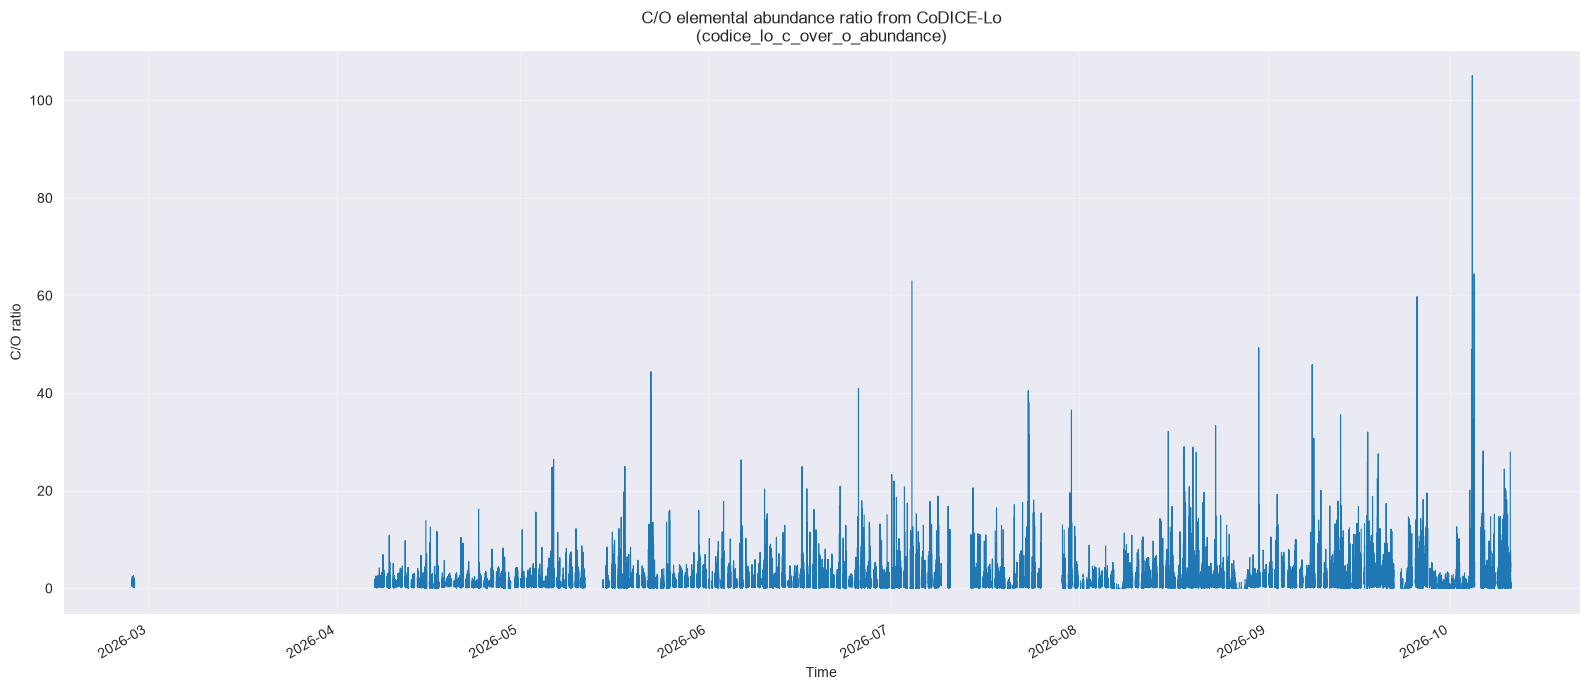

imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29.131435008'] -> ['2026-04-13T17:39:25.43

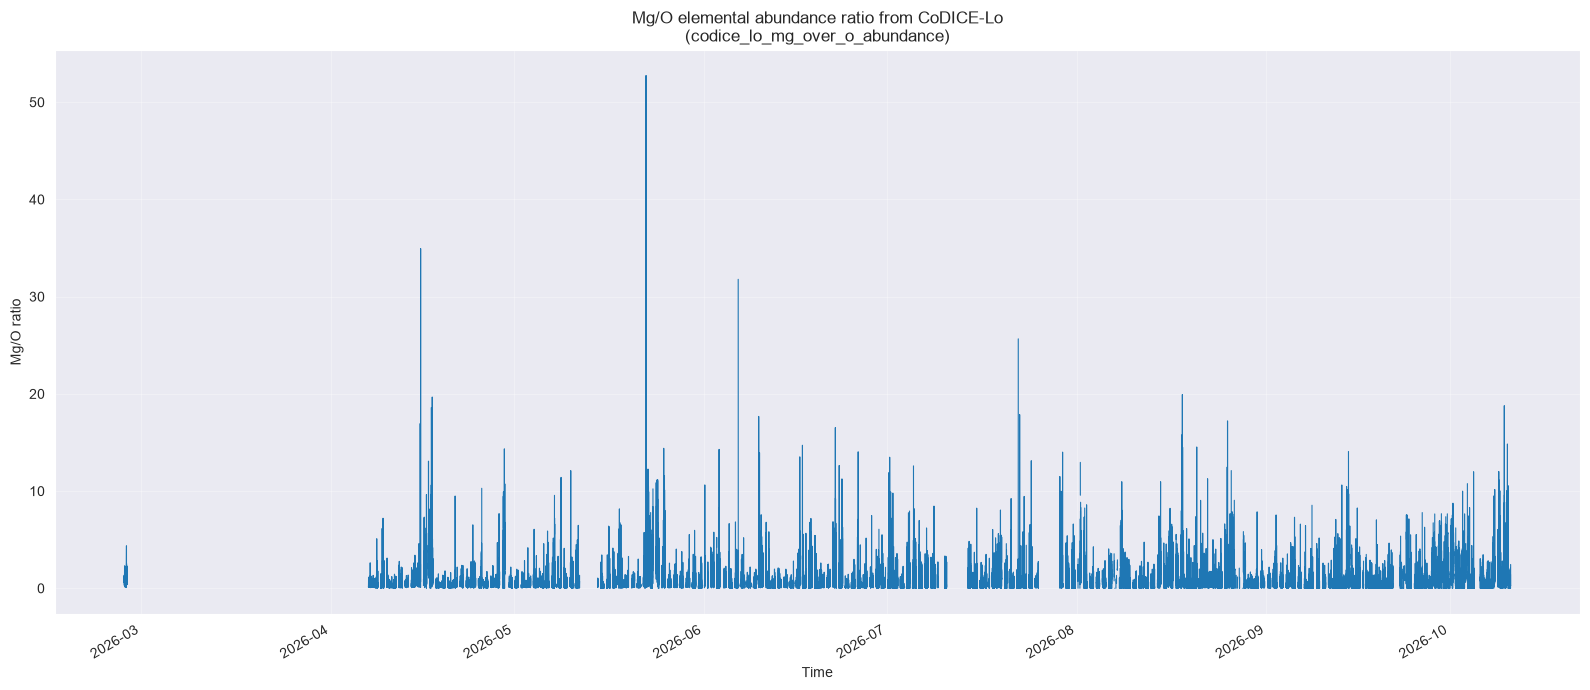

imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29.131435008'] -> ['2026-04-13T17:39:25.43

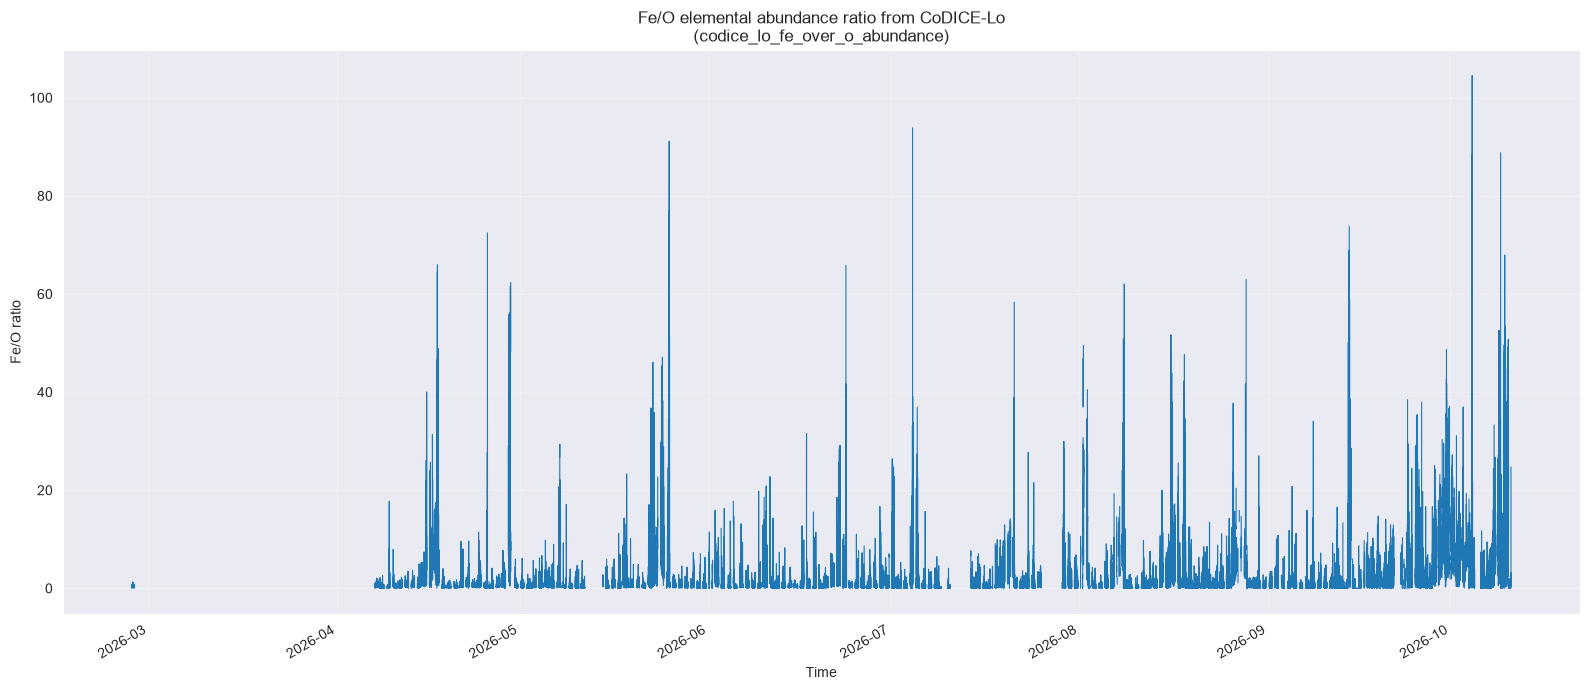


CoDICE-Lo - Charge state ratios
imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29.131435

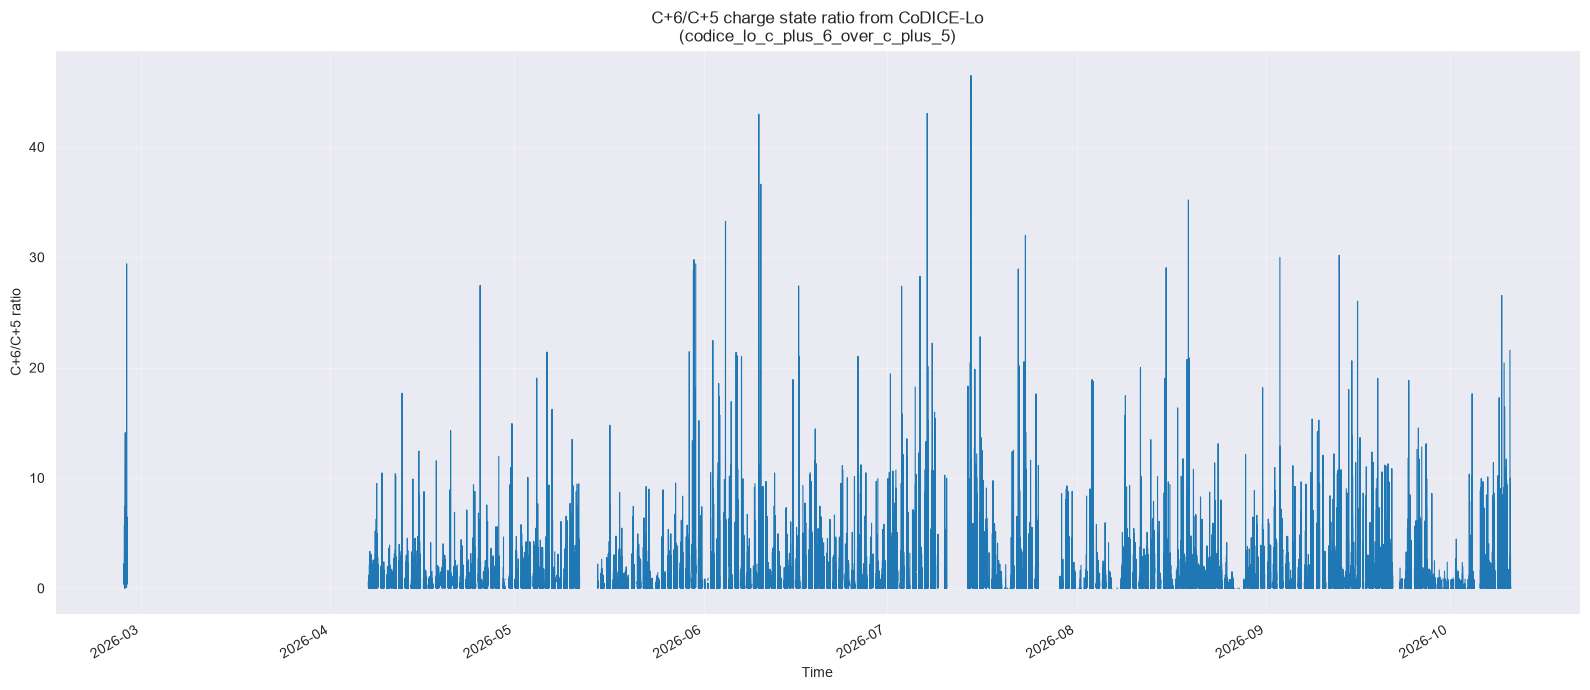

imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29.131435008'] -> ['2026-04-13T17:39:25.43

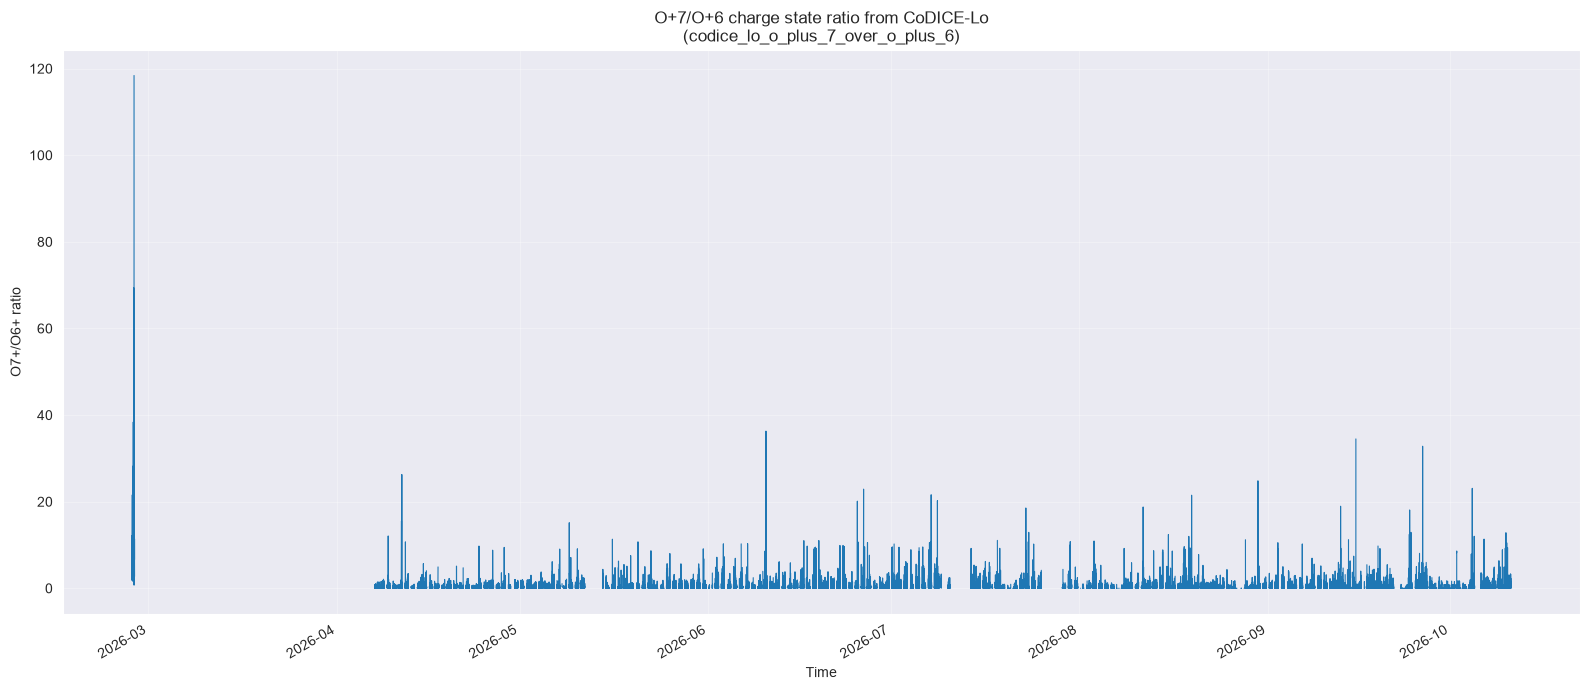

imap_ialirt_l1_realtime_20260226_v001.cdf: ['2026-02-26T05:51:08.886396672'] -> ['2026-02-26T17:05:58.738438144'] (162 samples)
imap_ialirt_l1_realtime_20260407_v001.cdf: ['2026-04-07T04:45:17.428138624'] -> ['2026-04-07T23:54:36.593529856'] (225 samples)
imap_ialirt_l1_realtime_20260408_v001.cdf: ['2026-04-08T01:02:30.869398656'] -> ['2026-04-08T17:37:08.441166464'] (224 samples)
imap_ialirt_l1_realtime_20260409_v001.cdf: ['2026-04-09T04:52:13.078542208'] -> ['2026-04-09T17:35:10.645037568'] (180 samples)
imap_ialirt_l1_realtime_20260410_v001.cdf: ['2026-04-10T04:34:16.688823552'] -> ['2026-04-10T23:56:42.230809856'] (198 samples)
imap_ialirt_l1_realtime_20260411_v001.cdf: ['2026-04-11T00:00:41.907797888'] -> ['2026-04-11T17:39:16.451886464'] (192 samples)
imap_ialirt_l1_realtime_20260412_v001.cdf: ['2026-04-12T04:34:24.125320832'] -> ['2026-04-12T17:41:21.297941888'] (193 samples)
imap_ialirt_l1_realtime_20260413_v001.cdf: ['2026-04-13T04:28:29.131435008'] -> ['2026-04-13T17:39:25.43

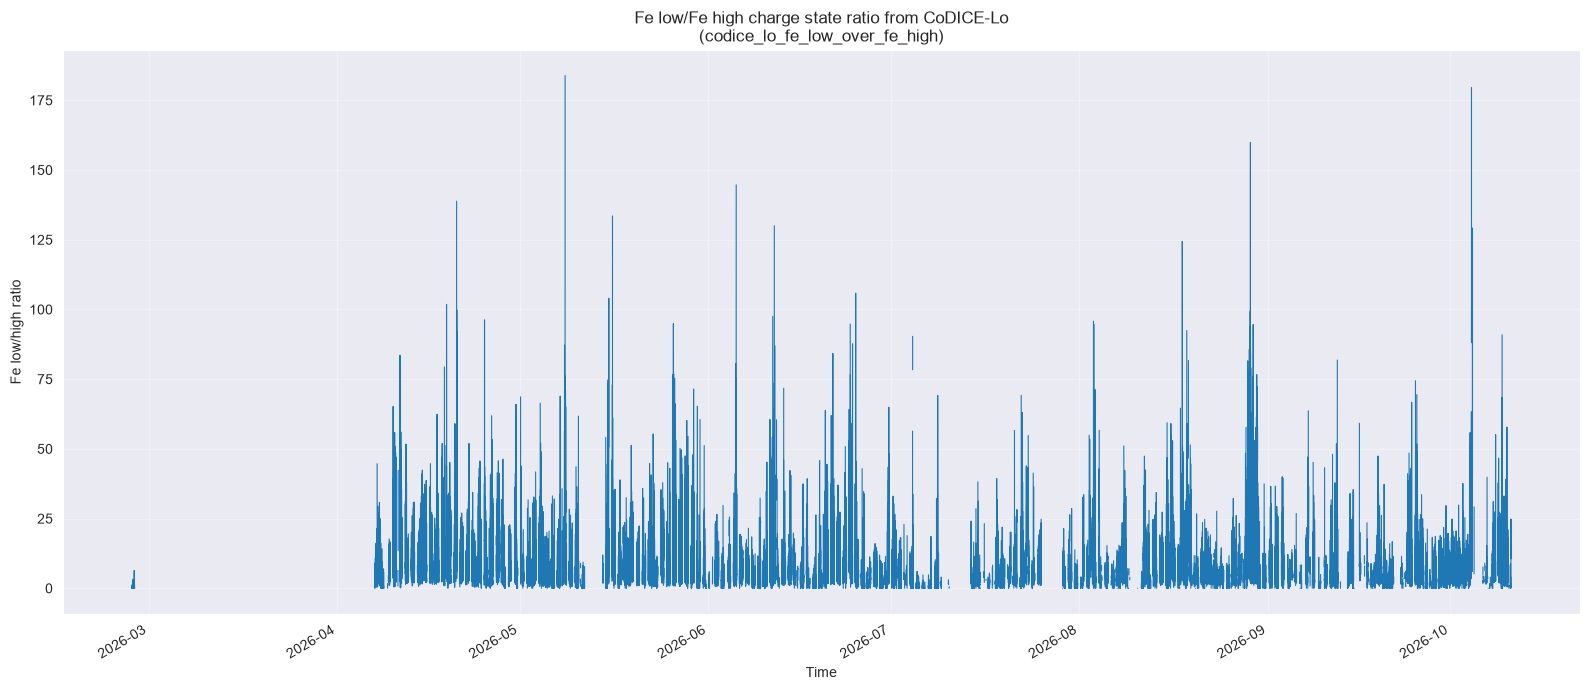

In [31]:
codice_lo = plot_codice_lo()

In [35]:
def plot_codice_hi_spectrogram(df, energy_edges, gap_factor=10,cmap="viridis"):
    df = df.sort_index()
    df = df.groupby(level=0).mean()
    time = mdates.date2num(df.index.to_pydatetime())
    values = df.to_numpy().T
    values = np.ma.masked_invalid(values)
    values = np.ma.masked_less_equal(values, 0)
    dt = np.diff(time)
    positive_dt = dt[dt > 0]
    if len(positive_dt) == 0:
        raise ValueError("No valid time differences.")

    median_dt = np.median(positive_dt)
    gap_indices = np.where(dt > gap_factor * median_dt)[0]
    starts = np.concatenate([[0], gap_indices + 1])
    ends = np.concatenate([gap_indices + 1, [len(time)]])
    positive_values = values.compressed()

    if len(positive_values) == 0:
        raise ValueError("No positive flux values.")

    vmin = np.percentile(positive_values, 2)
    vmax = np.percentile(positive_values, 99.5)
    norm = LogNorm(vmin=vmin, vmax=vmax)
    fig, ax = plt.subplots(figsize=(16, 7))
    mesh = None
    for start, end in zip(starts, ends):
        t = time[start:end]
        if len(t) == 0:
            continue
        if len(t) == 1:
            x_edges = np.array([t[0] - median_dt / 2, t[0] + median_dt / 2])
        else:
            x_edges = np.empty(len(t) + 1)
            x_edges[1:-1] = (t[:-1] + t[1:]) / 2
            x_edges[0] = t[0] - (t[1] - t[0]) / 2
            x_edges[-1] = t[-1] + (t[-1] - t[-2]) / 2
        mesh = ax.pcolormesh(x_edges, energy_edges, values[:, start:end], shading="flat", cmap=cmap, norm=norm)

    ax.set_yscale("log")
    ax.set_title("CoDICE-Hi — Proton energy-time spectrogram")
    ax.set_xlabel("Time")
    ax.set_ylabel("Proton energy [MeV]")
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label(
        r"Differential intensity "
        r"[counts / cm$^2$ sr s MeV]"
    )

    ax.xaxis_date()
    ax.grid(alpha=0.2)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [40]:
def get_codice_energy_bins(data_dir="../raw_data/ARCHIVE/All"):
    data_dir = Path(data_dir)
    cdf_files = sorted(p for p in data_dir.iterdir() if p.is_file() and p.suffix.lower() == ".cdf")
    for file in cdf_files:
        cdf = cdflib.CDF(str(file))
        try:
            variables = cdf.cdf_info().zVariables
            required = ["codice_hi_energy_center", "codice_hi_energy_minus","codice_hi_energy_plus"]
            if not all(v in variables for v in required):
                continue
            centers = np.asarray(cdf.varget("codice_hi_energy_center")).squeeze()
            minus = np.asarray(cdf.varget("codice_hi_energy_minus")).squeeze()
            plus = np.asarray(cdf.varget("codice_hi_energy_plus")).squeeze()

            lower_edges = centers - minus
            upper_edges = centers + plus
            energy_edges = np.concatenate([lower_edges, [upper_edges[-1]]])
            return centers, energy_edges
        except Exception as e:
            print(e)
    raise ValueError("No CoDICE-Hi energy bins found.")

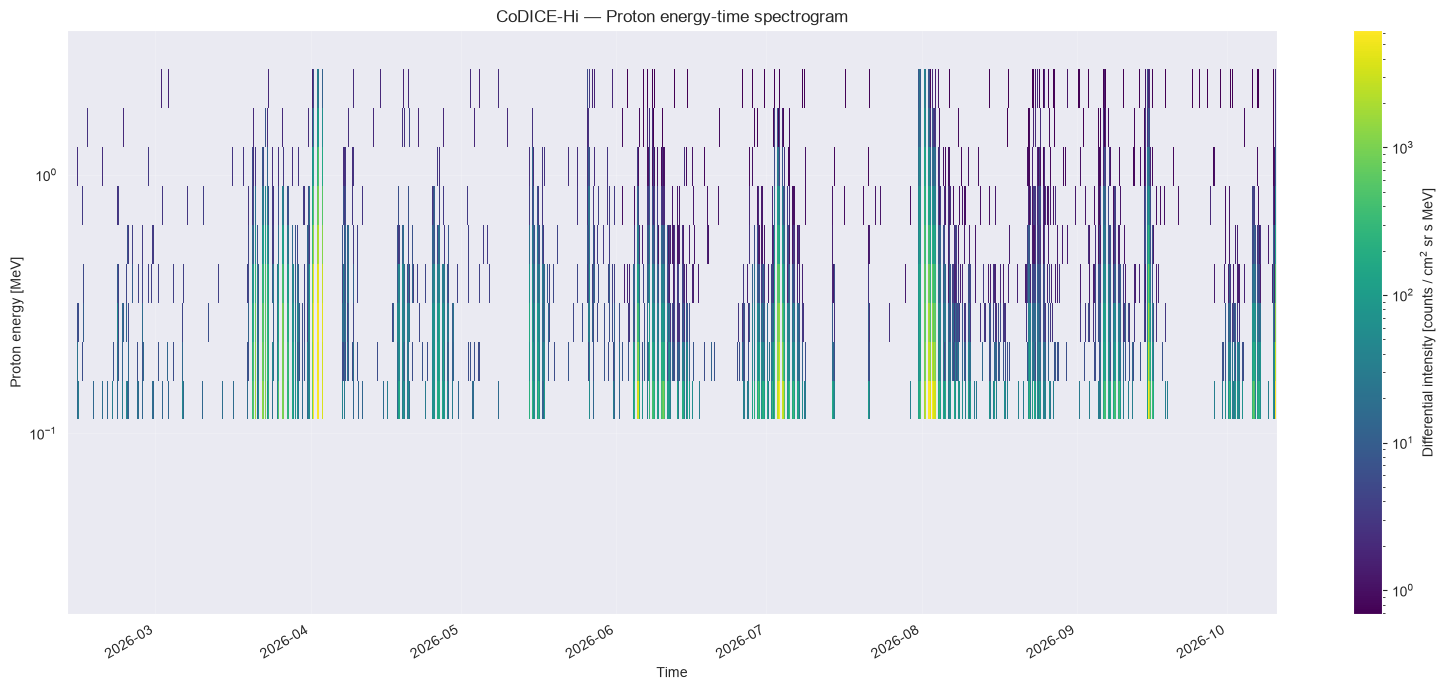

In [41]:
energy_centers, energy_edges = get_codice_energy_bins()
plot_codice_hi_spectrogram(codice_hi, energy_edges, gap_factor=10)

In [42]:
SWAPI_VARIABLES = {
    "density": {
        "title": "SWAPI - Solar wind proton density",
        "variable": "swapi_pseudo_proton_density",
        "label": "Proton density",
        "unit": "protons/cm³"
    },

    "speed": {
        "title": "SWAPI - Solar wind proton speed",
        "variable": "swapi_pseudo_proton_speed",
        "label": "Proton speed",
        "unit": "km/s"
    },

    "temperature": {
        "title": "SWAPI - Solar wind proton temperature",
        "variable": "swapi_pseudo_proton_temperature",
        "label": "Proton temperature",
        "unit": "K"
    }
}
def plot_swapi_time_series(data_dir="../raw_data/ARCHIVE/All", gap_factor=10):
    results = {}
    for name, config in SWAPI_VARIABLES.items():
        df = plot_time_series(config["variable"], data_dir=data_dir, gap_factor=gap_factor)
        results[name] = df

    return results

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:07.630878208'] -> ['2026-02-01T15:47:55.580761088'] (3198 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:55.528928000'] -> ['2026-02-02T23:59:55.478262272'] (2675 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:07.478251648'] -> ['2026-02-03T15:57:07.427605888'] (2949 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:58:19.376632576'] -> ['2026-02-04T22:59:19.328851584'] (2912 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:55.300495104'] -> ['2026-02-05T16:34:19.273016192'] (2576 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:52:19.224415744'] -> ['2026-02-06T18:59:19.189065344'] (3284 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:49:07.148318720'] -> ['2026-02-07T16:14:31.121540864'] (2528 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:55.072192000'] -> ['2026-02-08T23:5

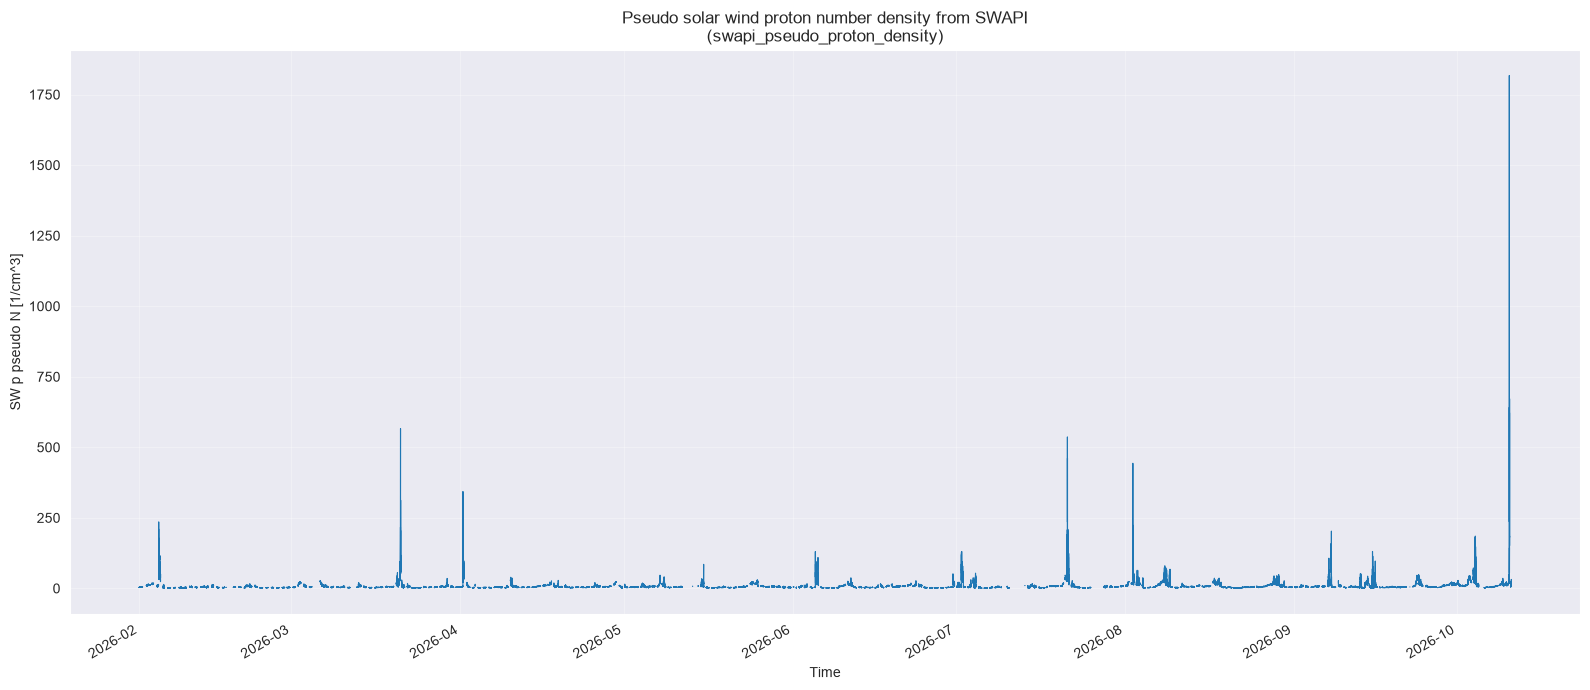

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:07.630878208'] -> ['2026-02-01T15:47:55.580761088'] (3198 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:55.528928000'] -> ['2026-02-02T23:59:55.478262272'] (2675 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:07.478251648'] -> ['2026-02-03T15:57:07.427605888'] (2949 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:58:19.376632576'] -> ['2026-02-04T22:59:19.328851584'] (2912 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:55.300495104'] -> ['2026-02-05T16:34:19.273016192'] (2576 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:52:19.224415744'] -> ['2026-02-06T18:59:19.189065344'] (3284 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:49:07.148318720'] -> ['2026-02-07T16:14:31.121540864'] (2528 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:55.072192000'] -> ['2026-02-08T23:5

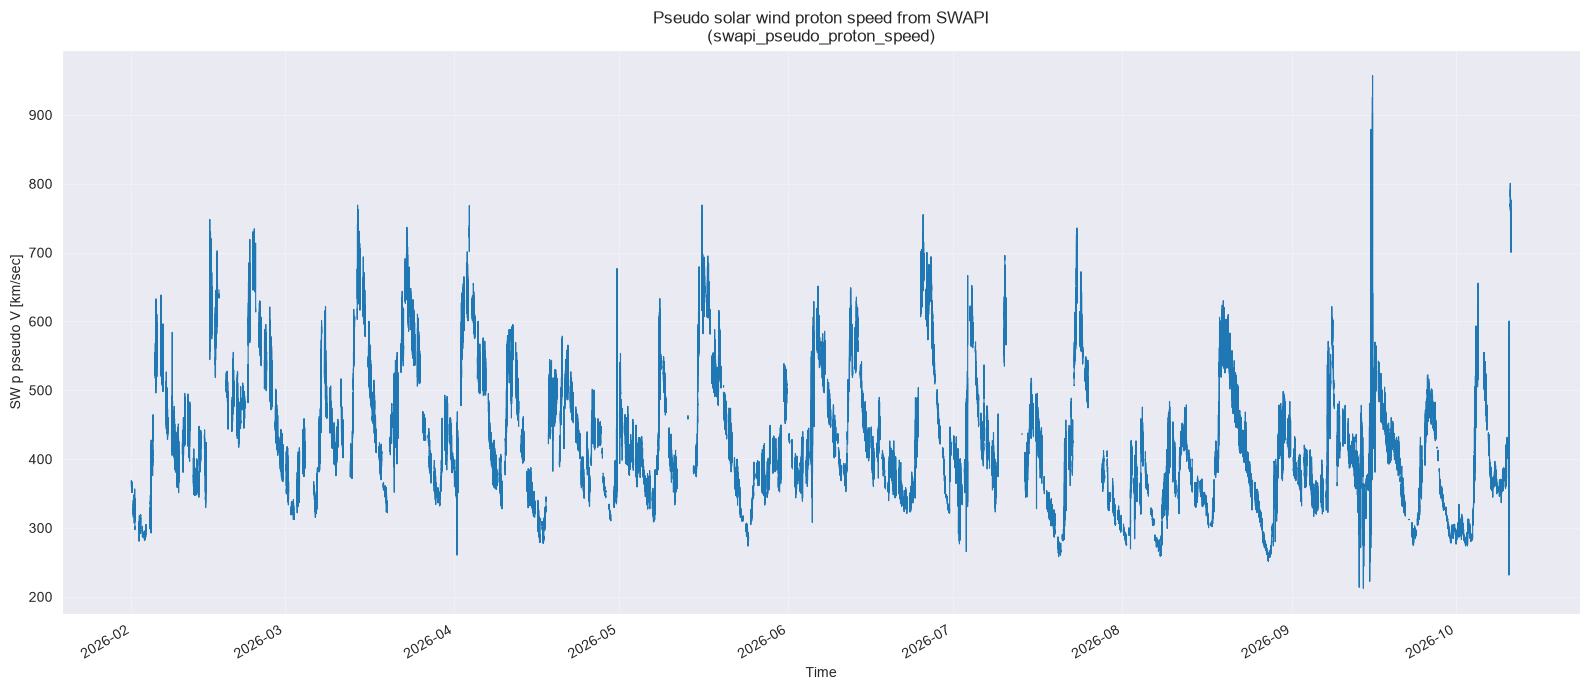

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:07.630878208'] -> ['2026-02-01T15:47:55.580761088'] (3198 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:55.528928000'] -> ['2026-02-02T23:59:55.478262272'] (2675 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:07.478251648'] -> ['2026-02-03T15:57:07.427605888'] (2949 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:58:19.376632576'] -> ['2026-02-04T22:59:19.328851584'] (2912 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:55.300495104'] -> ['2026-02-05T16:34:19.273016192'] (2576 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:52:19.224415744'] -> ['2026-02-06T18:59:19.189065344'] (3284 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:49:07.148318720'] -> ['2026-02-07T16:14:31.121540864'] (2528 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:55.072192000'] -> ['2026-02-08T23:5

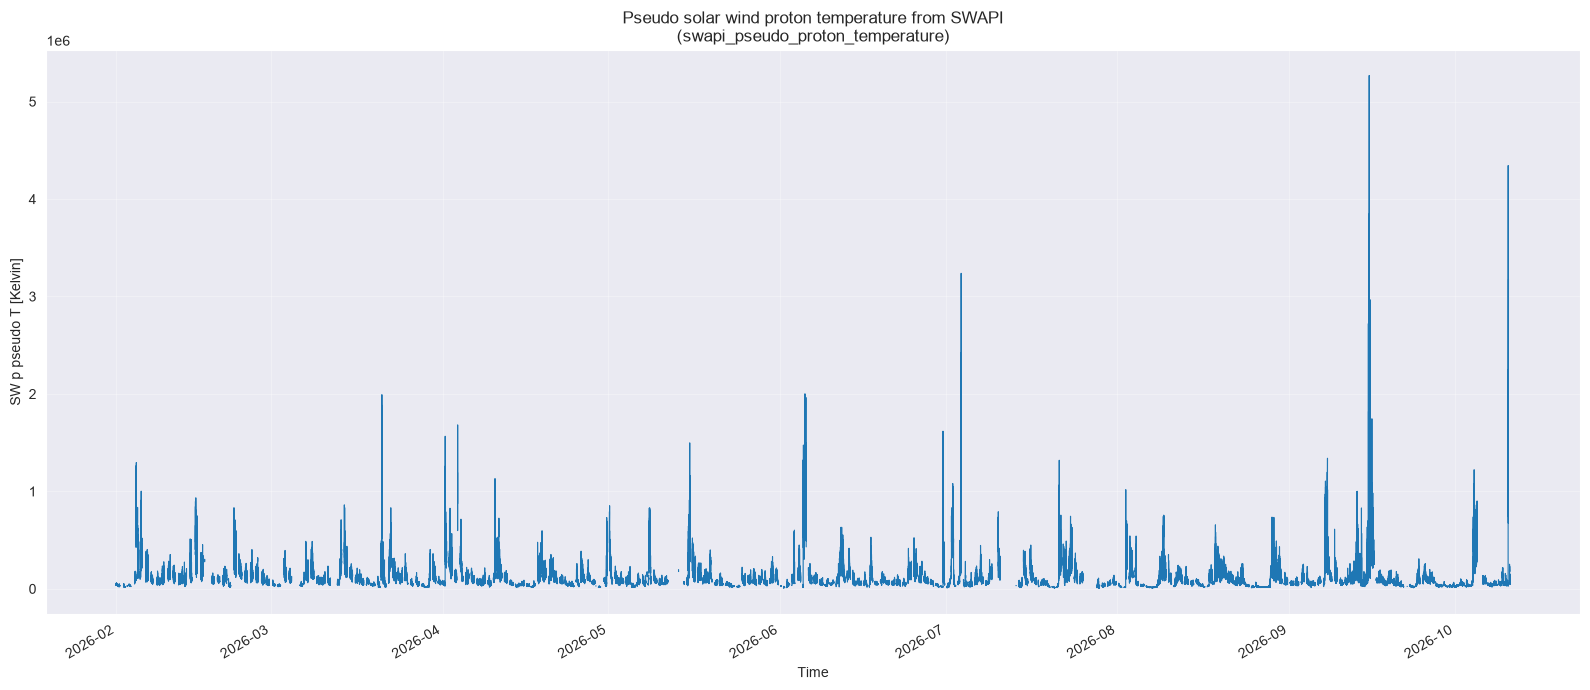

In [43]:
swapi = plot_swapi_time_series(data_dir="../raw_data/ARCHIVE/All")

In [44]:
def plot_swe_time_series(
    data_dir="../raw_data/ARCHIVE/All",
    gap_factor=10,
    log_scale=True
):
    data_dir = Path(data_dir)

    cdf_files = sorted(
        p for p in data_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".cdf"
    )

    all_time = []
    all_counts = []
    all_counterstreaming = []

    energy_centers = None
    files_counts = 0
    files_counter = 0

    for file in cdf_files:
        cdf = cdflib.CDF(str(file))

        try:
            info = cdf.cdf_info()
            variables = info.zVariables + info.rVariables

            # -------------------------------------------------
            # 1. Normalized electron counts
            # -------------------------------------------------
            if "swe_normalized_counts" in variables:

                attrs = cdf.varattsget("swe_normalized_counts")
                epoch_name = attrs.get("DEPEND_0")

                if epoch_name and epoch_name in variables:
                    epoch = np.asarray(cdf.varget(epoch_name))
                    counts = np.asarray(
                        cdf.varget("swe_normalized_counts"),
                        dtype=np.float64
                    )

                    fill_value = attrs.get("FILLVAL")

                    if fill_value is not None:
                        counts[counts == float(fill_value)] = np.nan

                    counts[~np.isfinite(counts)] = np.nan

                    valid_min = attrs.get("VALIDMIN")
                    valid_max = attrs.get("VALIDMAX")

                    if valid_min is not None:
                        counts[counts < valid_min] = np.nan

                    if valid_max is not None:
                        counts[counts > valid_max] = np.nan

                    if len(epoch) > 0 and len(epoch) == len(counts):
                        if energy_centers is None and "swe_electron_energy" in variables:
                            energy_centers = np.asarray(
                                cdf.varget("swe_electron_energy")
                            ).squeeze()

                        all_time.append(epoch)
                        all_counts.append(counts)
                        files_counts += 1

            # -------------------------------------------------
            # 2. Counterstreaming electrons
            # -------------------------------------------------
            if "swe_counterstreaming_electrons" in variables:

                attrs = cdf.varattsget(
                    "swe_counterstreaming_electrons"
                )

                epoch_name = attrs.get("DEPEND_0")

                if epoch_name and epoch_name in variables:
                    epoch = np.asarray(cdf.varget(epoch_name))

                    counter = np.asarray(
                        cdf.varget("swe_counterstreaming_electrons"),
                        dtype=np.float64
                    ).squeeze()

                    fill_value = attrs.get("FILLVAL")

                    if fill_value is not None:
                        counter[counter == float(fill_value)] = np.nan

                    valid_min = attrs.get("VALIDMIN")
                    valid_max = attrs.get("VALIDMAX")

                    if valid_min is not None:
                        counter[counter < valid_min] = np.nan

                    if valid_max is not None:
                        counter[counter > valid_max] = np.nan

                    if len(epoch) > 0 and len(epoch) == len(counter):
                        all_counterstreaming.append(
                            (epoch, counter)
                        )
                        files_counter += 1

        except Exception as ex:
            print(f"Error in {file.name}: {ex}")

    # =========================================================
    # 3. Combine normalized counts
    # =========================================================

    if not all_time:
        raise ValueError("No valid SWE normalized counts found.")

    all_time = np.concatenate(all_time)
    all_counts = np.concatenate(all_counts, axis=0)

    order = np.argsort(all_time)

    all_time = all_time[order]
    all_counts = all_counts[order]

    time = cdflib.cdfepoch.to_datetime(all_time)

    # Detect gaps
    if len(all_time) > 1 and gap_factor is not None:
        differences = np.diff(all_time)
        positive_differences = differences[differences > 0]

        if len(positive_differences):
            median_dt = np.median(positive_differences)

            gap_indices = np.where(
                differences > gap_factor * median_dt
            )[0]

            all_counts[gap_indices + 1, :] = np.nan

    if energy_centers is None:
        raise ValueError("SWE electron energy centers not found.")

    columns = [
        f"{energy:.1f} eV"
        for energy in energy_centers
    ]

    df_counts = pd.DataFrame(
        all_counts,
        index=pd.DatetimeIndex(time, name="time"),
        columns=columns
    )

    print(
        f"Normalized counts files: "
        f"{files_counts}/{len(cdf_files)}"
    )

    # =========================================================
    # 4. Plot normalized counts
    # =========================================================

    fig, ax = plt.subplots(figsize=(16, 7))

    for i, energy in enumerate(energy_centers):
        ax.plot(
            time,
            all_counts[:, i],
            linewidth=0.8,
            label=f"{energy:.1f} eV"
        )

    ax.set_title("SWE — Normalized electron counts")
    ax.set_xlabel("Time")
    ax.set_ylabel("Normalized counts")

    if log_scale:
        ax.set_yscale("log")

    ax.grid(True, alpha=0.3)
    ax.legend(title="Energy", ncol=4, fontsize=8)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    # =========================================================
    # 5. Combine counterstreaming data
    # =========================================================

    df_counter = None

    if all_counterstreaming:

        counter_time = np.concatenate(
            [item[0] for item in all_counterstreaming]
        )

        counter_values = np.concatenate(
            [item[1] for item in all_counterstreaming]
        )

        order = np.argsort(counter_time)

        counter_time = counter_time[order]
        counter_values = counter_values[order]

        counter_datetime = cdflib.cdfepoch.to_datetime(
            counter_time
        )

        if len(counter_time) > 1 and gap_factor is not None:
            differences = np.diff(counter_time)
            positive_differences = differences[differences > 0]

            if len(positive_differences):
                median_dt = np.median(positive_differences)

                gap_indices = np.where(
                    differences > gap_factor * median_dt
                )[0]

                counter_values[gap_indices + 1] = np.nan

        df_counter = pd.Series(
            counter_values,
            index=pd.DatetimeIndex(
                counter_datetime,
                name="time"
            ),
            name="counterstreaming"
        )

        print(
            f"Counterstreaming files: "
            f"{files_counter}/{len(cdf_files)}"
        )

        # Plot binary variable
        fig, ax = plt.subplots(figsize=(16, 4))

        ax.step(
            counter_datetime,
            counter_values,
            where="post",
            linewidth=0.8
        )

        ax.set_title("SWE — Counterstreaming electrons")
        ax.set_xlabel("Time")
        ax.set_ylabel("Counterstreaming")
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.2, 1.2)

        ax.grid(True, alpha=0.3)

        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()

    return {
        "normalized_counts": df_counts,
        "counterstreaming": df_counter,
        "energy_centers": energy_centers
    }

Normalized counts files: 241/245


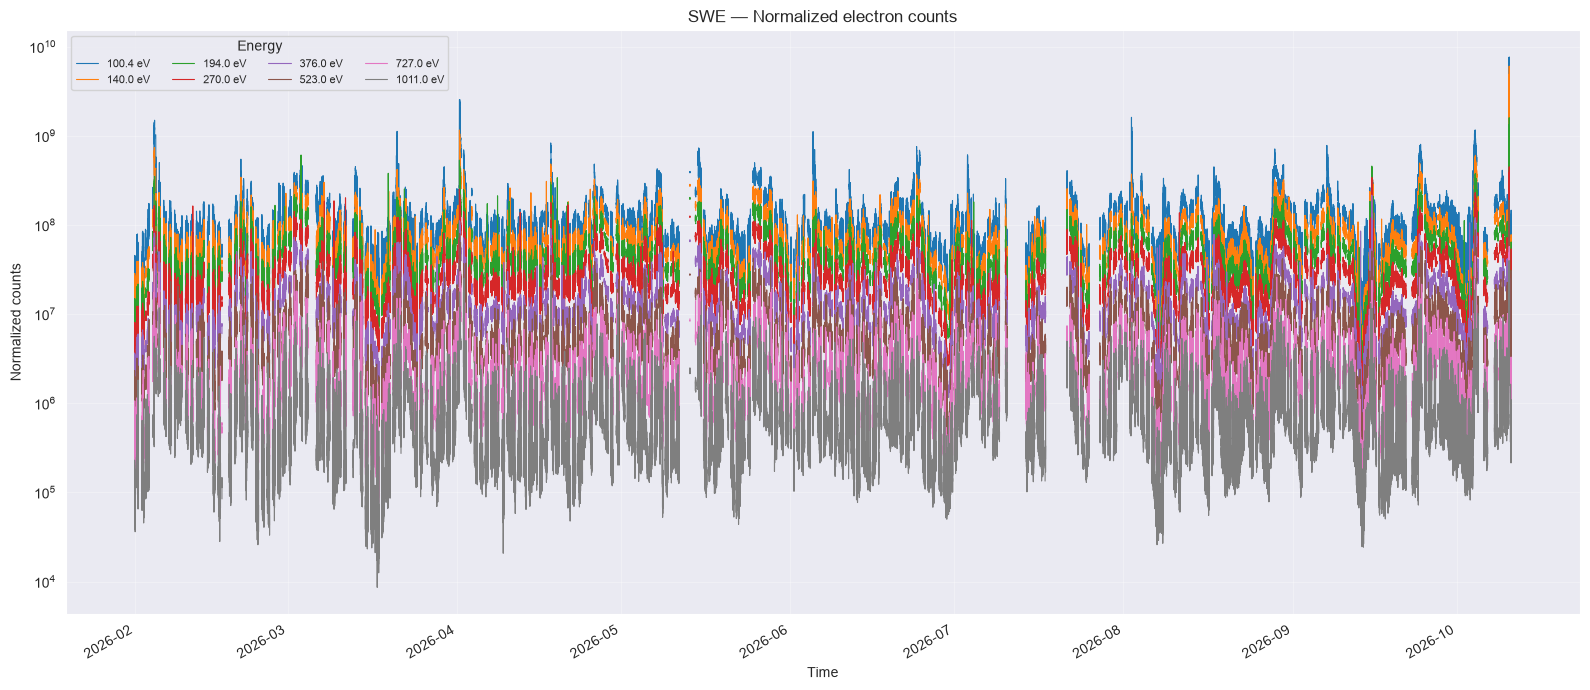

Counterstreaming files: 241/245


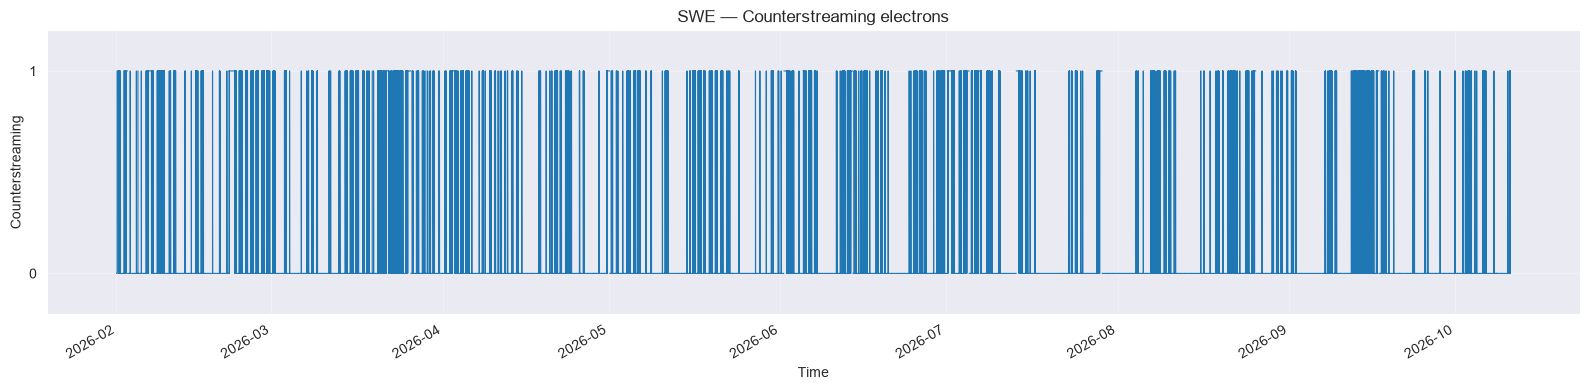

In [45]:
swe = plot_swe_time_series(
    data_dir="../raw_data/ARCHIVE/All",
    gap_factor=10,
    log_scale=True
)